
# 03 — Score-CAM: Explanation Generation and Robustness Pilot

**Project:** When Stable Explanations Disagree: A Stability–Localization Disagreement Audit for Chest X-ray Classification

## Overview

This notebook implements Score-CAM to examine explanations generated by the ResNet-50 lung-opacity classifier trained in Notebook 02.

The broader project asks:

**Can an explanation remain stable under image corruption while losing alignment with radiologist-annotated opacity regions?**

Score-CAM is one of three explanation methods used to investigate this question, alongside Integrated Gradients and Occlusion Sensitivity.

## Purpose of This Notebook

This notebook develops and tests the Score-CAM explanation workflow using a pilot sample of 12 correctly classified held-out images:

- Six true-positive images.
- Six true-negative images.

The pilot evaluates explanation generation, visual localization, model prediction behavior, and explanation stability under Gaussian blur and Gaussian noise.

It also establishes reusable image selections and preprocessing utilities for later experiments.

## Experimental Setup

| Component | Description |
|---|---|
| Dataset | RSNA Pneumonia Detection Challenge |
| Classifier | Fixed ResNet-50 checkpoint from Notebook 02 |
| XAI method | Score-CAM |
| Target layer | `model.layer4[-1]` |
| Input dimensions | 384 × 320 pixels |
| Corruptions | Gaussian blur and Gaussian noise |
| Severity levels | Mild, moderate, and severe |
| Stability measure | Spearman rank correlation between original and corrupted Score-CAM maps |
| Localization reference | Radiologist-annotated lung-opacity bounding boxes |

## Relationship to the Final Project

The pilot sample is not the full research evaluation.

The subsequent XAI evaluation uses 300 held-out images, including 150 positive and 150 negative cases.

The primary disagreement audit uses 150 annotated positive images across three XAI methods and six corruption conditions, producing 2,700 repeated evaluations.

The larger audit compares explanation stability with localization alignment. This notebook primarily establishes the Score-CAM implementation and initial experimental procedures.


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder"
)

DATA_DIR = PROJECT_DIR / "Data"
MODEL_DIR = PROJECT_DIR / "Models"
RESULTS_DIR = PROJECT_DIR / "Results"

print("Project folder exists:", PROJECT_DIR.exists())
print("Best model exists:", (MODEL_DIR / "resnet50_best.pth").exists())
print("Dataset splits exist:", (DATA_DIR / "model_dataset_split.csv").exists())
print("Test predictions exist:", (RESULTS_DIR / "resnet50_test_predictions.csv").exists())

Mounted at /content/drive
Project folder exists: True
Best model exists: True
Dataset splits exist: True
Test predictions exist: True


In [ ]:
%pip install -q grad-cam pydicom

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 73.4 MB/s eta 0:00:00


## 1. Environment Setup and Model Initialization

We begin by connecting Google Colab to Google Drive, where the dataset, trained model, and experimental results are stored.

After installing the required dependencies, we initialize PyTorch and load the best-performing ResNet-50 checkpoint saved during model training.

The model is placed in evaluation mode to ensure consistent inference and explanation generation.

### Image Preprocessing

Chest X-ray images are stored in DICOM format and require preprocessing before being passed to the model.

The preprocessing pipeline:

1. Reads the DICOM image and corrects inverted grayscale intensities when necessary.
2. Normalizes pixel intensities to the range [0, 1].
3. Resizes images to 384 × 320 pixels.
4. Replicates the grayscale image across three channels.
5. Applies the normalization used during model training.

Maintaining consistent preprocessing is important because Score-CAM explanations should reflect the behavior of the trained model rather than differences introduced by preprocessing.

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import pydicom
import cv2
import matplotlib.pyplot as plt

from torchvision.models import resnet50
from torchvision import transforms
from pytorch_grad_cam import ScoreCAM

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch version:", torch.__version__)
print("Score-CAM import successful!")

Device: cuda
PyTorch version: 2.11.0+cu130
Score-CAM import successful!


In [ ]:
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [ ]:
# Recreate the same ResNet-50 architecture used during training
model = resnet50(weights=None, num_classes=1)

# Load the best model from Notebook 02
best_model_path = MODEL_DIR / "resnet50_best.pth"

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

# Move model to GPU and switch to evaluation mode
model = model.to(device)
model.eval()

print("Best ResNet-50 loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print(f"Validation AUROC: {checkpoint['best_val_auc']:.4f}")
print("Model device:", next(model.parameters()).device)

Best ResNet-50 loaded successfully!
Best epoch: 1
Validation AUROC: 0.8864
Model device: cuda:0


In [ ]:
import numpy as np
import cv2
import pydicom
import torch

from torchvision import transforms

def load_dicom(path):
    ds = pydicom.dcmread(str(path))
    image = ds.pixel_array.astype(np.float32)

    # Invert images stored with reversed brightness
    if ds.PhotometricInterpretation == "MONOCHROME1":
        image = image.max() - image

    # Normalize image intensities to [0, 1]
    min_val = image.min()
    max_val = image.max()

    if max_val > min_val:
        image = (image - min_val) / (max_val - min_val)
    else:
        image = np.zeros_like(image)

    return image


class MedicalImageTransform:
    def __init__(self):
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __call__(self, image):
        image = cv2.resize(
            np.asarray(image, dtype=np.float32),
            (384, 320),
            interpolation=cv2.INTER_AREA
        )

        image = np.stack([image, image, image], axis=0)

        return self.normalize(
            torch.from_numpy(image).float()
        )


medical_transform = MedicalImageTransform()

print("DICOM loading function ready!")
print("Medical image transformation ready!")

DICOM loading function ready!
Medical image transformation ready!


In [ ]:
# Load test predictions saved from Notebook 02
test_results = pd.read_csv(
    RESULTS_DIR / "resnet50_test_predictions.csv"
)

print("Number of test images:", len(test_results))
print("Columns:", test_results.columns.tolist())

Number of test images: 4453
Columns: ['study_uid', 'series_uid', 'sop_uid', 'final_label', 'target', 'image_path', 'patient_id', 'split', 'predicted_probability', 'predicted_class']


In [ ]:
LOCAL_EXTRACT_DIR = Path("/content/rsna_local/extracted")

dicom_files = list(LOCAL_EXTRACT_DIR.rglob("*.dcm"))

print("Local DICOM files:", len(dicom_files))
print("First file:", dicom_files[0].name if dicom_files else "None")

Local DICOM files: 0
First file: None


In [ ]:
import shutil
import zipfile
import time
from pathlib import Path

ZIP_PATH = DATA_DIR / "pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip"

LOCAL_DIR = Path("/content/rsna_local")
LOCAL_ZIP = LOCAL_DIR / ZIP_PATH.name
LOCAL_EXTRACT_DIR = LOCAL_DIR / "extracted"

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

start = time.time()

# Copy ZIP from Google Drive to Colab's faster local storage
if not LOCAL_ZIP.exists():
    print("Copying ZIP from Google Drive...")
    shutil.copy2(ZIP_PATH, LOCAL_ZIP)

# Extract only if the DICOM files are missing
existing_count = sum(1 for _ in LOCAL_EXTRACT_DIR.rglob("*.dcm"))

if existing_count < 30000:
    print("Extracting DICOM images...")
    with zipfile.ZipFile(LOCAL_ZIP, "r") as zip_ref:
        zip_ref.extractall(LOCAL_EXTRACT_DIR)

dicom_count = sum(1 for _ in LOCAL_EXTRACT_DIR.rglob("*.dcm"))

print("DICOM files available:", dicom_count)
print(f"Elapsed time: {(time.time() - start) / 60:.2f} minutes")

Copying ZIP from Google Drive...
Extracting DICOM images...
DICOM files available: 30000
Elapsed time: 2.19 minutes


## 2. Generating Score-CAM Explanations

Score-CAM is a post-hoc explainability method that identifies image regions contributing to a CNN's prediction.

The method uses activation maps from a convolutional layer to construct spatial masks. These masks are applied to the input image and evaluated by the model to estimate their importance.

For this experiment, we use the final convolutional block of ResNet-50 (`layer4[-1]`) as the target layer.

### Initial Explanation

We begin by selecting a correctly classified positive chest X-ray from the test set.

The image is passed through the trained ResNet-50 model, and Score-CAM generates a heatmap showing the spatial regions contributing to the positive-class score.

Three visualizations are produced:

- **Original image:** The chest X-ray before explanation.
- **Score-CAM heatmap:** The spatial importance scores generated by Score-CAM.
- **Overlay:** The heatmap superimposed on the original X-ray to facilitate visual interpretation.

Regions with higher heatmap values indicate stronger contributions to the target class score.

These visualizations provide an initial qualitative assessment of the regions used by the model when predicting lung opacity.


### Explanation Targets and Interpretation

The classifier produces a single logit for lung opacity.

For positive cases, Score-CAM targets the positive-class logit.

For negative cases, the explanation target is the negative of that logit, corresponding to evidence favoring the absence of lung opacity.

The same trained classifier is used for both groups, with model parameters held fixed during explanation generation.

Score-CAM heatmaps identify spatial regions associated with the selected model output. They should not automatically be interpreted as clinically valid explanations or proof of causal importance.

The selected target layer is `model.layer4[-1]`, the final residual block of ResNet-50.


### Related Work: Score-CAM in Chest X-ray Classification

Score-CAM has been applied in medical imaging to visualize regions influencing CNN predictions for chest X-ray classification.

The study *Towards Explainable Artificial Intelligence for Pneumonia and Tuberculosis Classification from Chest X-Ray* (2023) applied Score-CAM to explain CNN predictions for pneumonia and tuberculosis.

This provides domain-specific motivation for using Score-CAM in the present project.

However, generating a visually interpretable heatmap does not establish that the explanation is reliable under image corruption.

Our project extends this evaluation perspective by examining whether Score-CAM explanations can remain stable while losing spatial alignment with radiologist-annotated opacity regions.

**Reference:**

Wang, H., Wang, Z., Du, M., Yang, F., Zhang, Z., Ding, S., Mardziel, P., & Hu, X. (2020). Score-CAM: Score-weighted visual explanations for convolutional neural networks. *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition Workshops*.

*Towards Explainable Artificial Intelligence for Pneumonia and Tuberculosis Classification from Chest X-Ray.* (2023). IEEE International Conference on Information and Communication Technology for Development for Africa (ICT4DA).

DOI: https://doi.org/10.1109/ICT4DA59526.2023.10302183


In [ ]:
# Select a correctly predicted positive test image
positive_cases = test_results[
    (test_results["target"] == 1) &
    (test_results["predicted_class"] == 1)
].copy()

print("Correctly predicted positive cases:", len(positive_cases))

# Select the first eligible image
selected_case = positive_cases.iloc[0]

selected_uid = selected_case["sop_uid"]

# Find the DICOM using its unique identifier
matches = list(LOCAL_EXTRACT_DIR.rglob(f"{selected_uid}.dcm"))

assert len(matches) == 1, (
    f"Expected one DICOM for {selected_uid}, found {len(matches)}"
)

selected_path = matches[0]

print("Selected image:", selected_uid)
print("Actual label:", selected_case["target"])
print("Predicted probability:",
      round(selected_case["predicted_probability"], 4))
print("DICOM file found:", selected_path.exists())

Correctly predicted positive cases: 897
Selected image: 1.2.276.0.7230010.3.1.4.8323329.30110.1517874495.744471
Actual label: 1
Predicted probability: 0.857
DICOM file found: True


Original image shape: (1024, 1024)
Model input shape: torch.Size([1, 3, 320, 384])


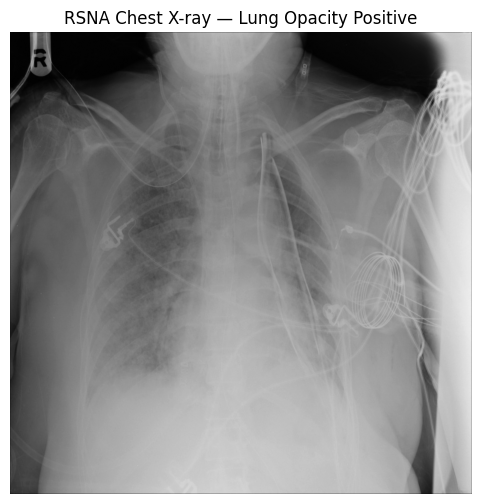

In [ ]:
# Load the original X-ray
original_image = load_dicom(selected_path)

# Apply the same preprocessing used during training
input_tensor = medical_transform(original_image)

# Add the batch dimension
input_batch = input_tensor.unsqueeze(0).to(device)

print("Original image shape:", original_image.shape)
print("Model input shape:", input_batch.shape)

plt.figure(figsize=(6, 6))
plt.imshow(original_image, cmap="gray")
plt.title("RSNA Chest X-ray — Lung Opacity Positive")
plt.axis("off")
plt.show()

In [ ]:
from pytorch_grad_cam import ScoreCAM

model.eval()

target_layers = [model.layer4[-1]]

cam = ScoreCAM(
    model=model,
    target_layers=target_layers
)

cam.batch_size = 16

print("Score-CAM initialized successfully!")
print("Target layer:", target_layers[0].__class__.__name__)

Score-CAM initialized successfully!
Target layer: Bottleneck


In [ ]:
import time

class PositiveClassTarget:
    def __call__(self, model_output):
        return model_output.reshape(-1)[0]

start_time = time.time()

heatmap = cam(
    input_tensor=input_batch,
    targets=[PositiveClassTarget()]
)[0]

elapsed = time.time() - start_time

print("Heatmap shape:", heatmap.shape)
print(f"Score-CAM runtime: {elapsed:.1f} seconds")
print("Heatmap range:", heatmap.min(), heatmap.max())

100%|██████████| 128/128 [00:16<00:00,  7.96it/s]

Heatmap shape: (320, 384)
Score-CAM runtime: 18.8 seconds
Heatmap range: 0.0 0.9999999


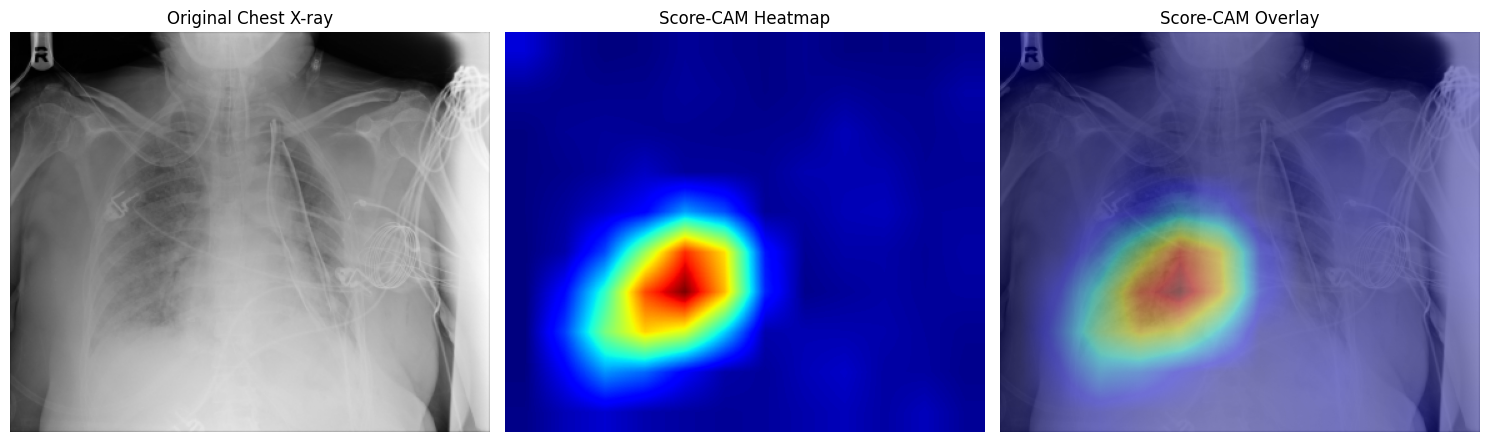

In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

# Resize original X-ray to match the Score-CAM heatmap
display_image = cv2.resize(
    original_image,
    (384, 320),
    interpolation=cv2.INTER_AREA
)

# Convert the grayscale X-ray into RGB
display_rgb = np.stack(
    [display_image, display_image, display_image],
    axis=-1
)

# Plot the original image, heatmap, and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(display_image, cmap="gray")
axes[0].set_title("Original Chest X-ray")

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Score-CAM Heatmap")

axes[2].imshow(display_rgb)
axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title("Score-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
SCORECAM_DIR = RESULTS_DIR / "ScoreCAM"
SCORECAM_DIR.mkdir(parents=True, exist_ok=True)

figure_path = SCORECAM_DIR / f"scorecam_example_{selected_uid}.png"

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

print("Visualization saved:", figure_path.exists())

Visualization saved: True


In [ ]:
# Search for annotation files without reading the DICOM images
annotation_files = [
    path for path in LOCAL_EXTRACT_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".csv", ".json"}
]

print("Annotation files found:", len(annotation_files))

for path in annotation_files[:20]:
    print(path.relative_to(LOCAL_EXTRACT_DIR))

Annotation files found: 0


## 3. Comparing Score-CAM Explanations with Ground Truth Annotations

To investigate whether the model focuses on clinically relevant image regions, we compare Score-CAM heatmaps with the available lung opacity annotations.

The annotation file contains information about annotated regions in the chest X-ray images. These annotations allow us to visualize the location of lung opacities alongside the regions highlighted by Score-CAM.


### Quantitative Localization Alignment

In addition to visual inspection, we calculate the proportion of Score-CAM attribution magnitude located inside radiologist-annotated opacity bounding boxes.

Localization alignment is defined as:

$$
\text{Alignment} =
\frac{\sum_{p \in B} |A(p)|}
{\sum_{p \in I} |A(p)|}
$$

where:

- \(A(p)\) represents the attribution value at pixel \(p\).
- \(B\) represents the union of annotated opacity regions.
- \(I\) represents the full image.

Higher values indicate that a larger share of the explanation is concentrated inside annotated regions.

The pilot localization results are saved to `localization_alignment_six_images.csv`.

### Interpretation and Limitations

Radiologist bounding boxes provide a reference for the spatial location of annotated lung opacities, but they are not pixel-level segmentation masks.

An explanation may highlight medically relevant context outside the boxes. Conversely, an explanation overlapping the boxes does not necessarily establish that the model is reasoning correctly.

Therefore, localization alignment is treated as a spatial evaluation measure, not a direct measure of clinical correctness or explanation faithfulness.


In [ ]:
import json

ANNOTATION_PATH = (
    DATA_DIR /
    "pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
)

print("Annotation file exists:", ANNOTATION_PATH.exists())

with open(ANNOTATION_PATH, "r") as f:
    annotations = json.load(f)

print("Top-level data type:", type(annotations).__name__)

if isinstance(annotations, dict):
    print("Top-level keys:", list(annotations.keys())[:15])

elif isinstance(annotations, list):
    print("Number of records:", len(annotations))
    print("First record:", annotations[0])

Annotation file exists: True
Top-level data type: dict
Top-level keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'isPrivate', 'labelGroups', 'datasets']


In [ ]:
datasets = annotations["datasets"]

print("Datasets type:", type(datasets).__name__)

if isinstance(datasets, list):
    print("Number of datasets:", len(datasets))

    for i, dataset in enumerate(datasets[:3]):
        print(f"\nDataset {i}:")
        print("Keys:", list(dataset.keys()))

        for key, value in dataset.items():
            if isinstance(value, list):
                print(f"  {key}: list with {len(value)} items")
            elif isinstance(value, dict):
                print(f"  {key}: dictionary with {len(value)} keys")

elif isinstance(datasets, dict):
    print("Dataset keys:", list(datasets.keys())[:15])

Datasets type: list
Number of datasets: 1

Dataset 0:
Keys: ['id', 'type', 'createdAt', 'updatedAt', 'name', 'description', 'studies', 'annotations']
  studies: list with 30000 items
  annotations: list with 83809 items


In [ ]:
dataset = annotations["datasets"][0]

studies = dataset["studies"]
annotation_records = dataset["annotations"]

print("FIRST STUDY")
print("Keys:", list(studies[0].keys()))

for key, value in studies[0].items():
    if isinstance(value, (str, int, float, bool)) or value is None:
        print(f"{key}: {str(value)[:150]}")
    else:
        print(f"{key}: {type(value).__name__}")

print("\nFIRST ANNOTATION")
print("Keys:", list(annotation_records[0].keys()))

for key, value in annotation_records[0].items():
    if isinstance(value, (str, int, float, bool)) or value is None:
        print(f"{key}: {str(value)[:150]}")
    else:
        print(f"{key}: {type(value).__name__}")

FIRST STUDY
Keys: ['StudyInstanceUID', 'number', 'findings']
StudyInstanceUID: 1.2.276.0.7230010.3.1.2.8323329.7188.1517874330.219668
number: 7
findings: 

FIRST ANNOTATION
Keys: ['id', 'createdAt', 'createdById', 'updatedAt', 'updatedById', 'machineLearningModelId', 'StudyInstanceUID', 'SeriesInstanceUID', 'SOPInstanceUID', 'labelId', 'annotationNumber', 'height', 'width', 'data', 'note', 'radlexTagIds', 'reviewsPositiveCount', 'reviewsNegativeCount']
id: A_e5227e
createdAt: 2018-03-24T23:00:19.392Z
createdById: U_rk3
updatedAt: 2018-03-24T23:00:19.398Z
updatedById: U_rk3
machineLearningModelId: None
StudyInstanceUID: 1.2.276.0.7230010.3.1.2.8323329.6749.1517874327.608586
SeriesInstanceUID: 1.2.276.0.7230010.3.1.3.8323329.6749.1517874327.608585
SOPInstanceUID: 1.2.276.0.7230010.3.1.4.8323329.6749.1517874327.608587
labelId: L_1el
annotationNumber: None
height: None
width: None
data: None
note: None
radlexTagIds: list
reviewsPositiveCount: 0
reviewsNegativeCount: 0


In [ ]:
selected_annotations = [
    record
    for record in annotation_records
    if str(record.get("SOPInstanceUID")) == str(selected_uid)
]

print("Annotations for selected image:", len(selected_annotations))

for i, record in enumerate(selected_annotations):
    print(f"\nAnnotation {i + 1}")
    print("Label ID:", record.get("labelId"))
    print("Data:", str(record.get("data"))[:500])
    print("Height:", record.get("height"))
    print("Width:", record.get("width"))

Annotations for selected image: 4

Annotation 1
Label ID: L_v8n
Data: {'x': 505.11211, 'y': 399.49776, 'width': 242.2242, 'height': 414.4215}
Height: 1024
Width: 1024

Annotation 2
Label ID: L_rjp
Data: {'x': 166.4574, 'y': 215.82063, 'width': 292.73543, 'height': 619.91028}
Height: 1024
Width: 1024

Annotation 3
Label ID: L_rjp
Data: {'x': 505.11211, 'y': 399.49776, 'width': 242.2242, 'height': 414.4215}
Height: 1024
Width: 1024

Annotation 4
Label ID: L_v8n
Data: {'x': 166.4574, 'y': 215.82063, 'width': 292.73543, 'height': 619.91028}
Height: 1024
Width: 1024


In [ ]:
label_groups = annotations["labelGroups"]

print("Label groups type:", type(label_groups).__name__)

if isinstance(label_groups, list):
    print("Number of label groups:", len(label_groups))

    for group in label_groups:
        print("\nGroup:", group.get("name"))
        print("Keys:", list(group.keys()))

        labels = group.get("labels", [])

        for label in labels:
            if label.get("id") in {"L_v8n", "L_rjp"}:
                print("MATCHING LABEL:", label)

elif isinstance(label_groups, dict):
    print("Keys:", list(label_groups.keys()))

Label groups type: list
Number of label groups: 7

Group: Default group
Keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'labels']

Group: QA
Keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'labels']

Group: Team 1
Keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'labels']
MATCHING LABEL: {'id': 'L_rjp', 'createdAt': '2018-03-16T23:41:27.045Z', 'updatedAt': '2018-05-25T01:42:29.996Z', 'name': 'Lung Opacity (Med Prob)', 'description': '', 'color': '#ffcdd2', 'type': 'local', 'scope': 'instance', 'annotationMode': 'bbox', 'radlexTagIds': ['RID28530', 'RID28538', 'RID5350']}

Group: Team 2
Keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'labels']

Group: Team 2a
Keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'labels']

Group: Calculated
Keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'labels']
MATCHING LABEL: {'id': 'L_v8n', 'createdAt': '2018-06-13T18:12:12.089Z', 'updatedAt': '2018-06-26T14:51:48.818Z', '

Final lung-opacity bounding boxes: 2


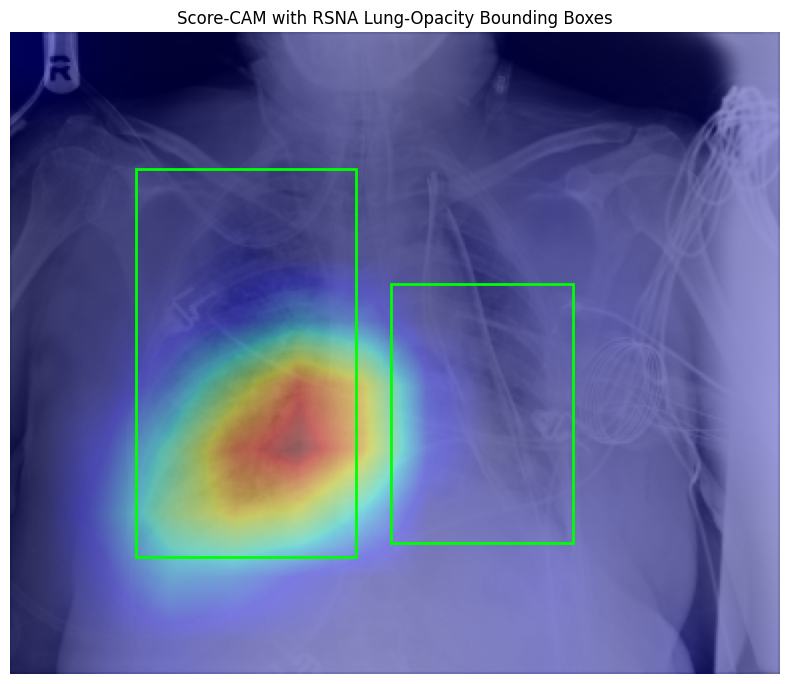

In [ ]:
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import numpy as np

# Use only the final Calculated lung-opacity annotations
opacity_boxes = [
    record for record in selected_annotations
    if record["labelId"] == "L_v8n"
    and isinstance(record.get("data"), dict)
]

print("Final lung-opacity bounding boxes:", len(opacity_boxes))

fig, ax = plt.subplots(figsize=(8, 7))

# Display the resized X-ray
ax.imshow(display_image, cmap="gray")

# Overlay the existing Score-CAM heatmap
ax.imshow(
    heatmap,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)

# Scale coordinates from original DICOM resolution
# to the 384 x 320 model input resolution
for record in opacity_boxes:
    box = record["data"]

    scale_x = 384 / record["width"]
    scale_y = 320 / record["height"]

    rect = Rectangle(
        (
            box["x"] * scale_x,
            box["y"] * scale_y
        ),
        box["width"] * scale_x,
        box["height"] * scale_y,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title(
    "Score-CAM with RSNA Lung-Opacity Bounding Boxes"
)
ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
output_path = SCORECAM_DIR / f"scorecam_with_boxes_{selected_uid}.png"

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

print("Saved:", output_path.exists())

Saved: True


In [ ]:
# Select six correctly predicted positive test images
sample_cases = (
    test_results[
        (test_results["target"] == 1) &
        (test_results["predicted_class"] == 1)
    ]
    .sample(n=6, random_state=42)
    .reset_index(drop=True)
)

print("Selected images:", len(sample_cases))

display(
    sample_cases[
        ["sop_uid", "target", "predicted_class"]
    ]
)

Selected images: 6


,sop_uid,target,predicted_class
0,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,1,1
1,1.2.276.0.7230010.3.1.4.8323329.23771.15178744...,1,1
2,1.2.276.0.7230010.3.1.4.8323329.2309.151787429...,1,1
3,1.2.276.0.7230010.3.1.4.8323329.11891.15178743...,1,1
4,1.2.276.0.7230010.3.1.4.8323329.3251.151787430...,1,1
5,1.2.276.0.7230010.3.1.4.8323329.25616.15178744...,1,1


100%|██████████| 128/128 [00:16<00:00,  7.75it/s]


Completed image 1/6


100%|██████████| 128/128 [00:16<00:00,  7.70it/s]


Completed image 2/6


100%|██████████| 128/128 [00:17<00:00,  7.42it/s]


...

Completed image 4/6


100%|██████████| 128/128 [00:16<00:00,  7.80it/s]


Completed image 5/6


100%|██████████| 128/128 [00:16<00:00,  7.82it/s]


Completed image 6/6


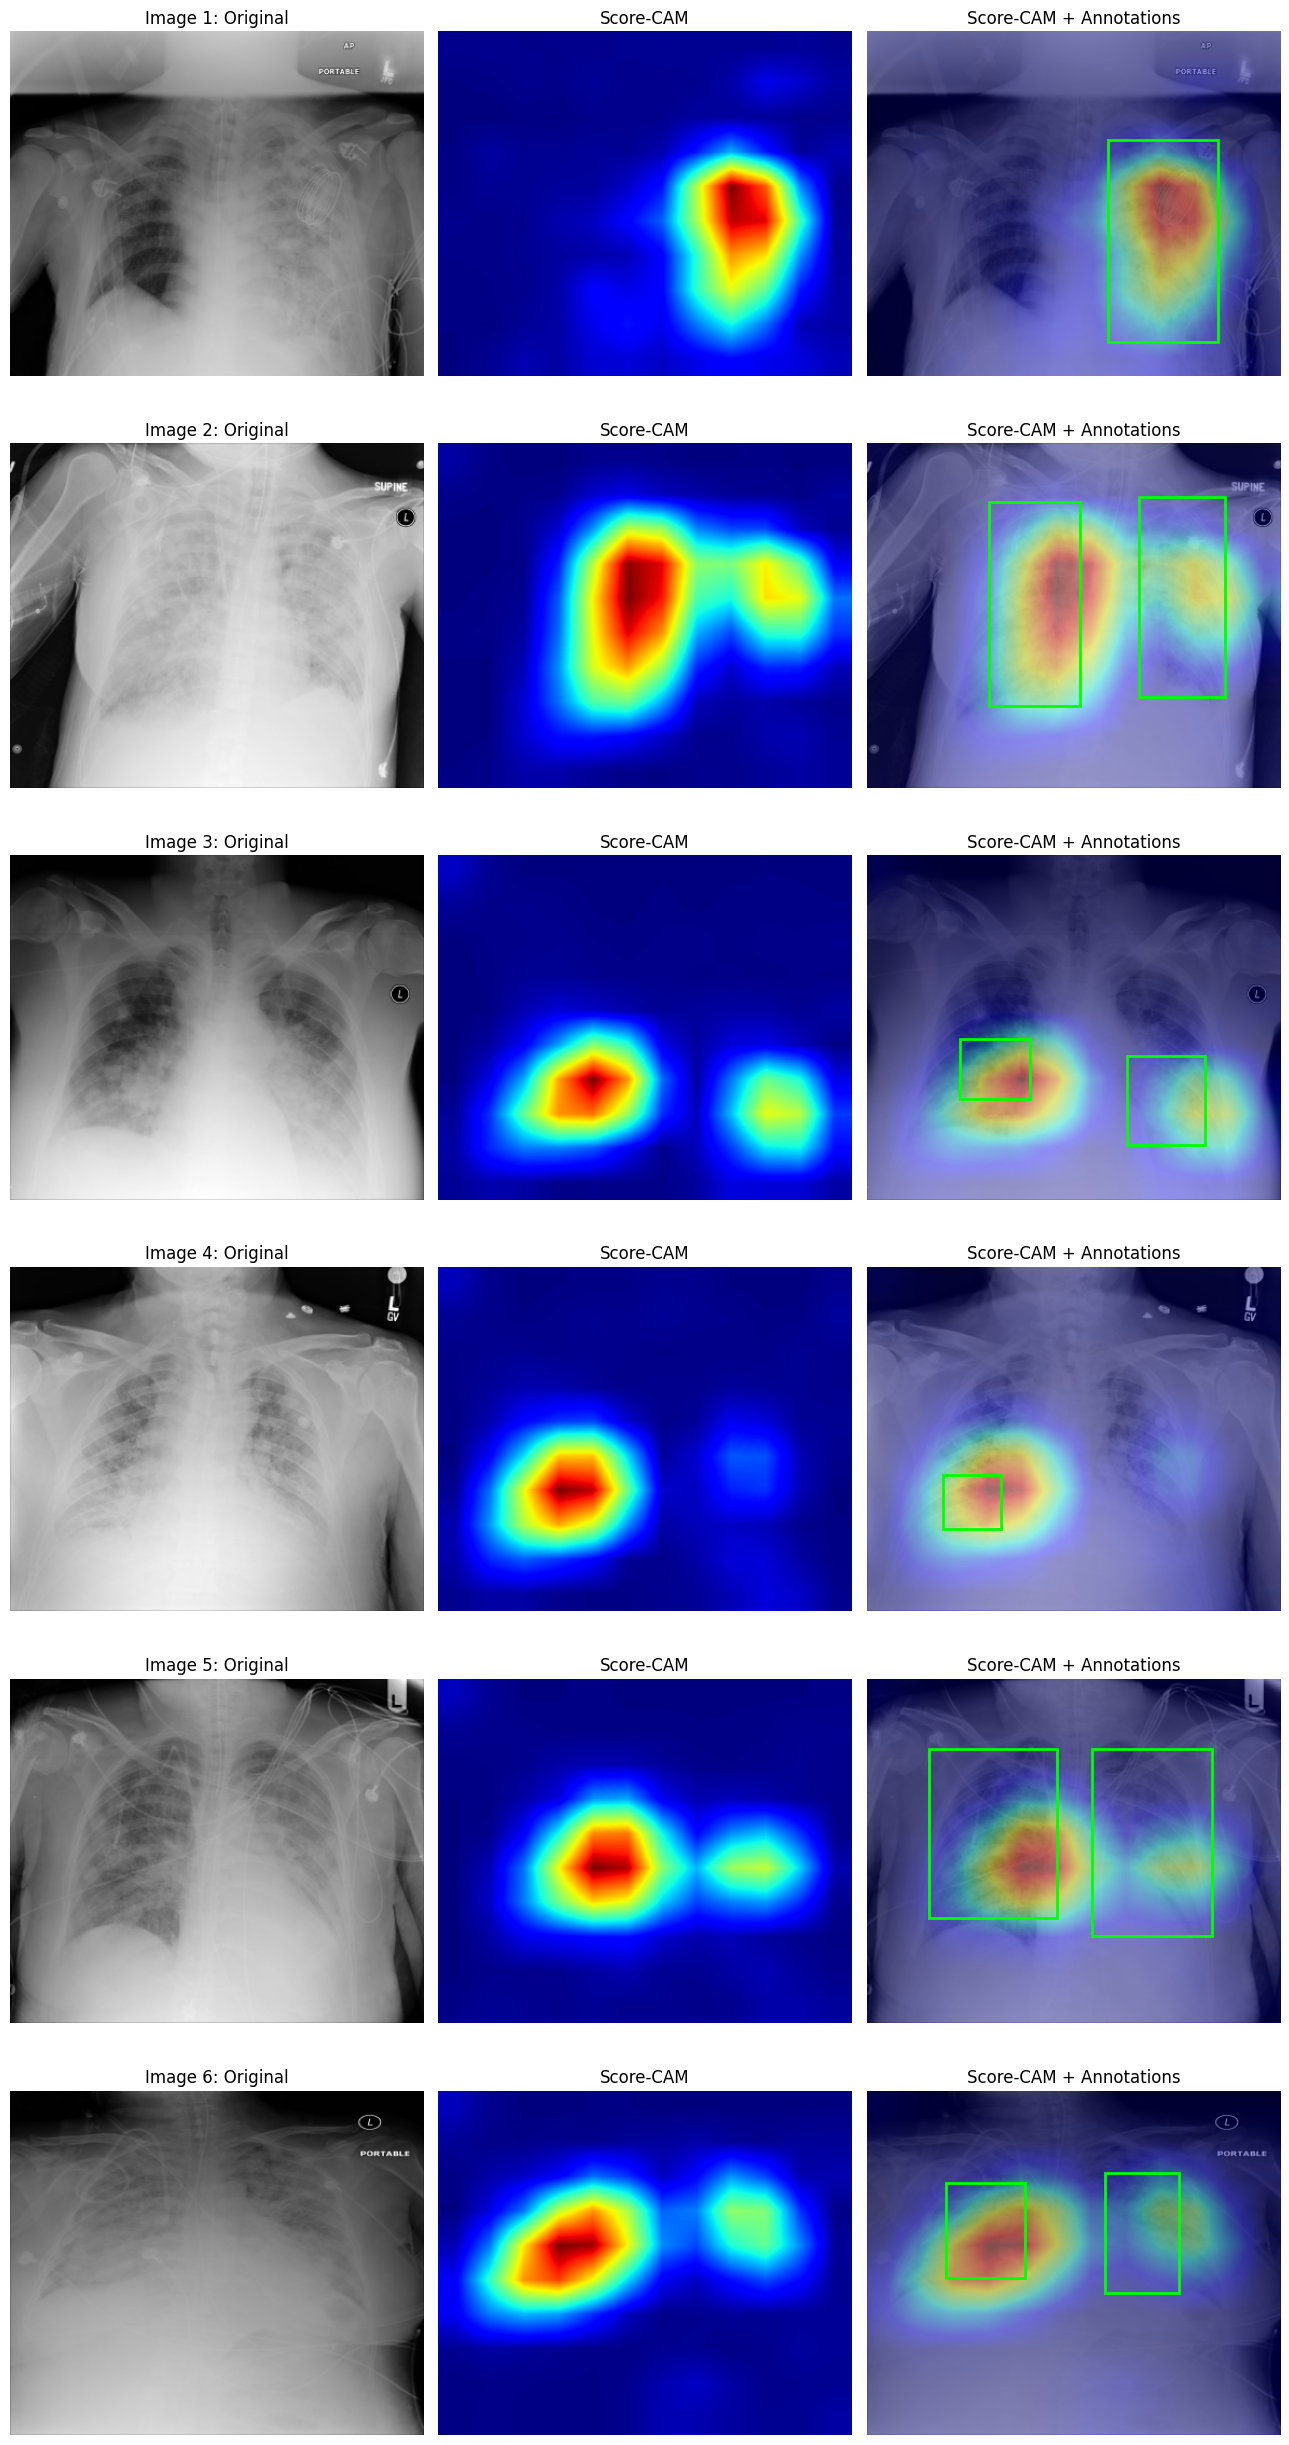

Gallery saved: True


In [ ]:
from matplotlib.patches import Rectangle

# Build a lookup of final lung-opacity bounding boxes
opacity_lookup = {}

for record in annotation_records:
    if (
        record.get("labelId") == "L_v8n"
        and isinstance(record.get("data"), dict)
    ):
        uid = str(record["SOPInstanceUID"])
        opacity_lookup.setdefault(uid, []).append(record)

# Index local DICOM files once, rather than searching repeatedly
dicom_lookup = {
    path.stem: path
    for path in LOCAL_EXTRACT_DIR.rglob("*.dcm")
}

fig, axes = plt.subplots(
    6, 3,
    figsize=(13, 25)
)

for i, row in sample_cases.iterrows():

    uid = str(row["sop_uid"])

    # Load image
    image_path = dicom_lookup[uid]
    image = load_dicom(image_path)

    display_img = cv2.resize(
        image, (384, 320),
        interpolation=cv2.INTER_AREA
    )

    # Apply the same preprocessing as model training
    tensor = medical_transform(image).unsqueeze(0).to(device)

    # Generate Score-CAM
    cam_map = cam(
        input_tensor=tensor,
        targets=[PositiveClassTarget()]
    )[0]

    # Column 1: Original X-ray
    axes[i, 0].imshow(display_img, cmap="gray")
    axes[i, 0].set_title(f"Image {i+1}: Original")

    # Column 2: Score-CAM heatmap
    axes[i, 1].imshow(cam_map, cmap="jet", vmin=0, vmax=1)
    axes[i, 1].set_title("Score-CAM")

    # Column 3: Overlay with bounding boxes
    ax = axes[i, 2]

    ax.imshow(display_img, cmap="gray")
    ax.imshow(cam_map, cmap="jet", alpha=0.4, vmin=0, vmax=1)

    for record in opacity_lookup.get(uid, []):
        box = record["data"]

        scale_x = 384 / record["width"]
        scale_y = 320 / record["height"]

        rect = Rectangle(
            (
                box["x"] * scale_x,
                box["y"] * scale_y
            ),
            box["width"] * scale_x,
            box["height"] * scale_y,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title("Score-CAM + Annotations")

    for j in range(3):
        axes[i, j].axis("off")

    print(f"Completed image {i+1}/6")

plt.tight_layout()

# Save directly to Google Drive
gallery_path = SCORECAM_DIR / "scorecam_six_image_gallery.png"

fig.savefig(
    gallery_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gallery saved:", gallery_path.exists())

In [ ]:
alignment_results = []

for i, row in sample_cases.iterrows():
    uid = str(row["sop_uid"])

    image = load_dicom(dicom_lookup[uid])
    tensor = medical_transform(image).unsqueeze(0).to(device)

    cam_map = cam(
        input_tensor=tensor,
        targets=[PositiveClassTarget()]
    )[0]

    # Create a mask covering the union of annotated boxes
    mask = np.zeros(cam_map.shape, dtype=np.uint8)
    h, w = mask.shape

    for record in opacity_lookup.get(uid, []):
        box = record["data"]

        sx = w / record["width"]
        sy = h / record["height"]

        x1 = int(np.floor(box["x"] * sx))
        y1 = int(np.floor(box["y"] * sy))
        x2 = int(np.ceil((box["x"] + box["width"]) * sx))
        y2 = int(np.ceil((box["y"] + box["height"]) * sy))

        x1, x2 = np.clip([x1, x2], 0, w)
        y1, y2 = np.clip([y1, y2], 0, h)

        mask[y1:y2, x1:x2] = 1

    total_attribution = cam_map.sum()

    alignment = (
        cam_map[mask == 1].sum() / total_attribution
        if total_attribution > 0 else np.nan
    )

    box_area_fraction = mask.mean()

    alignment_results.append({
        "image": i + 1,
        "sop_uid": uid,
        "alignment": float(alignment),
        "box_area_fraction": float(box_area_fraction)
    })

    print(f"Completed {i + 1}/6")

alignment_df = pd.DataFrame(alignment_results)

display(alignment_df.round(3))

100%|██████████| 128/128 [00:16<00:00,  7.82it/s]


Completed 1/6


100%|██████████| 128/128 [00:16<00:00,  7.67it/s]


Completed 2/6


100%|██████████| 128/128 [00:17<00:00,  7.51it/s]


...

100%|██████████| 128/128 [00:16<00:00,  7.93it/s]


Completed 5/6


100%|██████████| 128/128 [00:16<00:00,  7.90it/s]

Completed 6/6


,image,sop_uid,alignment,box_area_fraction
0,1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,0.654,0.158
1,2,1.2.276.0.7230010.3.1.4.8323329.23771.15178744...,0.596,0.255
2,3,1.2.276.0.7230010.3.1.4.8323329.2309.151787429...,0.276,0.080
3,4,1.2.276.0.7230010.3.1.4.8323329.11891.15178743...,0.164,0.023
4,5,1.2.276.0.7230010.3.1.4.8323329.3251.151787430...,0.685,0.314
5,6,1.2.276.0.7230010.3.1.4.8323329.25616.15178744...,0.369,0.119


In [ ]:
alignment_path = SCORECAM_DIR / "localization_alignment_six_images.csv"

alignment_df.to_csv(alignment_path, index=False)

print("Saved:", alignment_path.exists())
print("Mean alignment:", round(alignment_df["alignment"].mean(), 3))

Saved: True
Mean alignment: 0.457



### Pilot Sample Selection

The robustness pilot uses six correctly classified positive images and six correctly classified negative images from the held-out test set.

Positive image identifiers are retained from the earlier explanation and annotation analysis. Negative images are sampled from true-negative predictions using `random_state=42`.

The selected identifiers are saved so the same images can be reused across corruption experiments and explanation methods.

Because the pilot contains only correctly classified cases, its results should not be generalized to misclassified images or the full test population.

The larger XAI evaluation is conducted separately.

## 4. Explanation Robustness Under Gaussian Blur

We investigate whether Score-CAM explanations remain stable when chest X-rays are subjected to Gaussian blur.

Gaussian blur reduces fine image details by smoothing neighboring pixels. This allows us to examine whether the model's predictions and explanations depend on fine-grained visual information.

### Experimental Procedure

We apply four blur conditions to the selected images:

| Condition | Gaussian Sigma |
|---|---:|
| Original | 0.0 |
| Mild Blur | 0.5 |
| Moderate Blur | 1.5 |
| Severe Blur | 3.0 |

For each condition, we generate a Score-CAM explanation and record the model's predicted lung opacity probability.

### Explanation Stability

We measure explanation similarity using Spearman rank correlation between the original and corrupted Score-CAM heatmaps.

A higher correlation indicates that the spatial ranking of important image regions remains more consistent after corruption.

A lower correlation indicates that the explanation has changed more substantially.

By comparing prediction probabilities and explanation similarity, we can investigate whether the model maintains stable explanations even when its predictions remain unchanged.

The experiment is conducted on six correctly classified positive images.

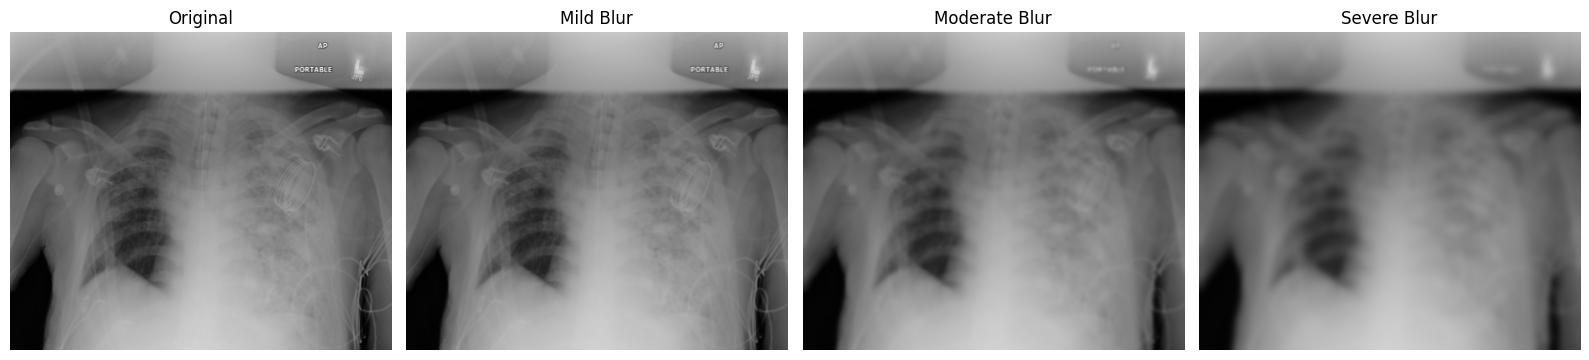

In [ ]:
# Select Image 1 from our six-image sample
test_uid = str(sample_cases.iloc[0]["sop_uid"])

# Load the original chest X-ray
original = load_dicom(dicom_lookup[test_uid])

# Resize to the model's input dimensions
original_resized = cv2.resize(
    original,
    (384, 320),
    interpolation=cv2.INTER_AREA
)

# Gaussian blur at three severity levels
blur_levels = {
    "Original": 0,
    "Mild Blur": 0.5,
    "Moderate Blur": 1.5,
    "Severe Blur": 3.0
}

blurred_images = {}

for name, sigma in blur_levels.items():

    if sigma == 0:
        corrupted = original_resized.copy()
    else:
        corrupted = cv2.GaussianBlur(
            original_resized,
            ksize=(0, 0),
            sigmaX=sigma,
            sigmaY=sigma
        )

    blurred_images[name] = corrupted

# Visualize
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (name, image) in zip(
    axes, blurred_images.items()
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Normalize the already-resized grayscale image
# using the same ImageNet statistics as training
def prepare_corrupted_image(image):
    rgb = np.stack([image, image, image], axis=0)

    tensor = torch.from_numpy(
        rgb.astype(np.float32)
    )

    return medical_transform.normalize(tensor)

prediction_results = []

model.eval()

with torch.no_grad():

    for name, image in blurred_images.items():

        tensor = (
            prepare_corrupted_image(image)
            .unsqueeze(0)
            .to(device)
        )

        logit = model(tensor).reshape(-1)[0]
        probability = torch.sigmoid(logit).item()

        prediction_results.append({
            "condition": name,
            "opacity_probability": probability,
            "predicted_class": int(probability >= 0.5)
        })

blur_predictions_df = pd.DataFrame(prediction_results)

display(blur_predictions_df.round(4))

,condition,opacity_probability,predicted_class
0,Original,0.8987,1
1,Mild Blur,0.8933,1
2,Moderate Blur,0.7122,1
3,Severe Blur,0.5791,1


In [ ]:
# Generate Score-CAM heatmaps for each blur condition
blur_heatmaps = {}

for name, image in blurred_images.items():

    tensor = (
        prepare_corrupted_image(image)
        .unsqueeze(0)
        .to(device)
    )

    heatmap_blur = cam(
        input_tensor=tensor,
        targets=[PositiveClassTarget()]
    )[0]

    blur_heatmaps[name] = heatmap_blur.copy()

    print(f"Completed: {name}")

print("All four Score-CAM explanations generated!")

100%|██████████| 128/128 [00:16<00:00,  7.76it/s]


Completed: Original


100%|██████████| 128/128 [00:16<00:00,  7.66it/s]


Completed: Mild Blur


100%|██████████| 128/128 [00:17<00:00,  7.42it/s]


Completed: Moderate Blur


100%|██████████| 128/128 [00:16<00:00,  7.82it/s]

Completed: Severe Blur
All four Score-CAM explanations generated!


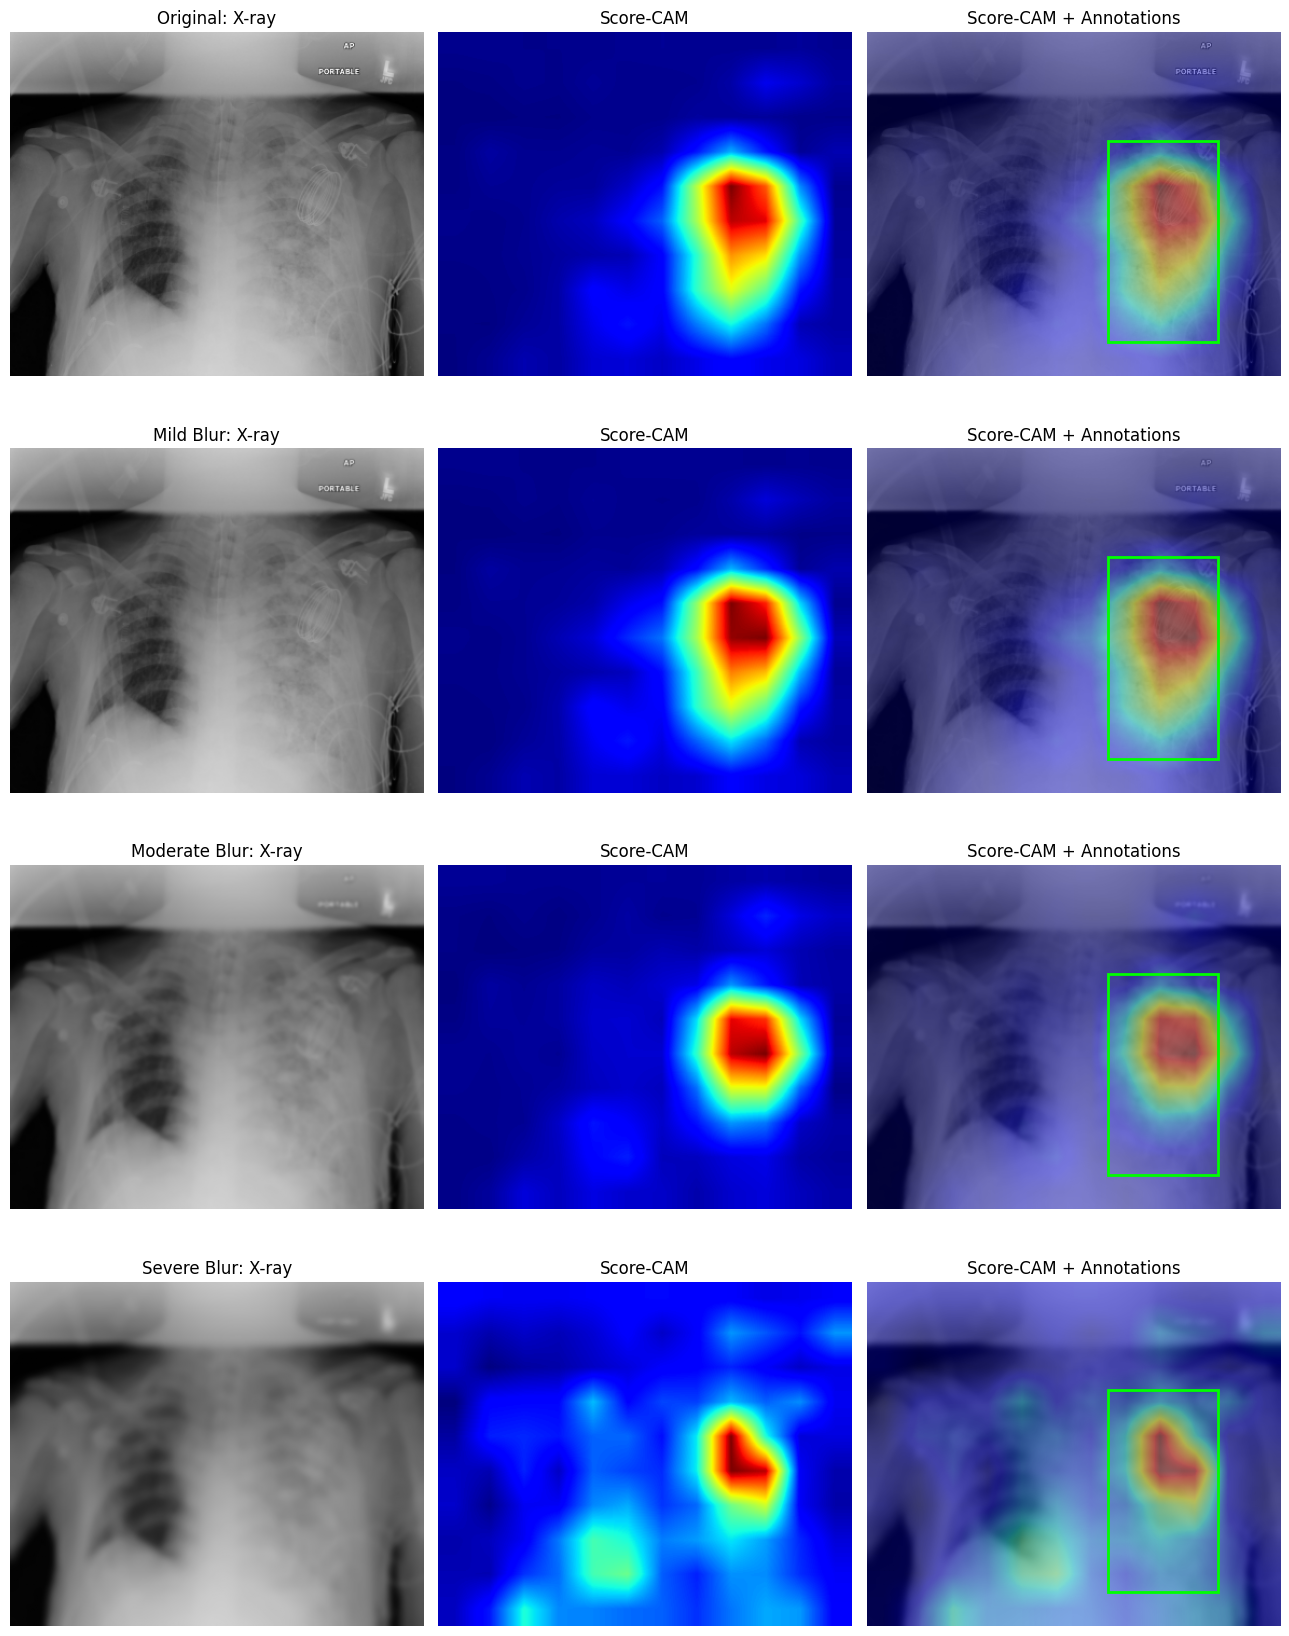

Saved: True


In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(13, 17))

for i, (name, image) in enumerate(blurred_images.items()):

    heatmap_blur = blur_heatmaps[name]

    # Original/corrupted X-ray
    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"{name}: X-ray")

    # Score-CAM heatmap
    axes[i, 1].imshow(
        heatmap_blur,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[i, 1].set_title("Score-CAM")

    # Overlay with radiologist annotations
    ax = axes[i, 2]
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.imshow(
        heatmap_blur,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )

    for record in opacity_lookup.get(test_uid, []):
        box = record["data"]

        scale_x = 384 / record["width"]
        scale_y = 320 / record["height"]

        rect = Rectangle(
            (box["x"] * scale_x, box["y"] * scale_y),
            box["width"] * scale_x,
            box["height"] * scale_y,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title("Score-CAM + Annotations")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()

# Save the visualization
blur_figure_path = SCORECAM_DIR / f"gaussian_blur_comparison_{test_uid}.png"

fig.savefig(blur_figure_path, dpi=150, bbox_inches="tight")

plt.show()

print("Saved:", blur_figure_path.exists())

In [ ]:
from scipy.stats import spearmanr

def calculate_alignment(cam_map, boxes):
    h, w = cam_map.shape
    mask = np.zeros((h, w), dtype=bool)

    for record in boxes:
        box = record["data"]

        sx = w / record["width"]
        sy = h / record["height"]

        x1 = int(np.floor(box["x"] * sx))
        y1 = int(np.floor(box["y"] * sy))
        x2 = int(np.ceil((box["x"] + box["width"]) * sx))
        y2 = int(np.ceil((box["y"] + box["height"]) * sy))

        x1, x2 = np.clip([x1, x2], 0, w)
        y1, y2 = np.clip([y1, y2], 0, h)

        mask[y1:y2, x1:x2] = True

    total = cam_map.sum()

    return (
        float(cam_map[mask].sum() / total)
        if total > 0 else np.nan
    )


original_cam = blur_heatmaps["Original"]
boxes = opacity_lookup.get(test_uid, [])

results = []

for name, cam_map in blur_heatmaps.items():

    alignment = calculate_alignment(cam_map, boxes)

    similarity = spearmanr(
        original_cam.flatten(),
        cam_map.flatten()
    ).statistic

    probability = blur_predictions_df.loc[
        blur_predictions_df["condition"] == name,
        "opacity_probability"
    ].iloc[0]

    results.append({
        "condition": name,
        "opacity_probability": probability,
        "localization_alignment": alignment,
        "explanation_similarity": similarity
    })

blur_analysis_df = pd.DataFrame(results)

display(blur_analysis_df.round(4))

# Save results
blur_analysis_df.to_csv(
    SCORECAM_DIR / f"gaussian_blur_analysis_{test_uid}.csv",
    index=False
)

,condition,opacity_probability,localization_alignment,explanation_similarity
0,Original,0.8987,0.6540,1.0000
1,Mild Blur,0.8933,0.6455,0.9944
2,Moderate Blur,0.7122,0.5833,0.9410
3,Severe Blur,0.5791,0.3380,0.8268


In [ ]:
# Reuse the functions and variables from previous steps:
# cam, model, device, sample_cases, dicom_lookup,
# prepare_corrupted_image, calculate_alignment,
# opacity_lookup, PositiveClassTarget

from scipy.stats import spearmanr

results_path = SCORECAM_DIR / "gaussian_blur_all_six.csv"

# Start with Image 1's completed results
all_results = []

for _, row in blur_analysis_df.iterrows():
    all_results.append({
        "image": 1,
        "sop_uid": str(sample_cases.iloc[0]["sop_uid"]),
        "condition": row["condition"],
        "opacity_probability": row["opacity_probability"],
        "localization_alignment": row["localization_alignment"],
        "explanation_similarity": row["explanation_similarity"]
    })

# Process Images 2 through 6
for i in range(1, 6):

    uid = str(sample_cases.iloc[i]["sop_uid"])
    original = load_dicom(dicom_lookup[uid])

    resized = cv2.resize(
        original, (384, 320),
        interpolation=cv2.INTER_AREA
    )

    heatmaps = {}

    for condition, sigma in blur_levels.items():

        if sigma == 0:
            image = resized.copy()
        else:
            image = cv2.GaussianBlur(
                resized, (0, 0),
                sigmaX=sigma,
                sigmaY=sigma
            )

        tensor = (
            prepare_corrupted_image(image)
            .unsqueeze(0)
            .to(device)
        )

        with torch.no_grad():
            logit = model(tensor).reshape(-1)[0]
            probability = torch.sigmoid(logit).item()

        heatmap = cam(
            input_tensor=tensor,
            targets=[PositiveClassTarget()]
        )[0].copy()

        heatmaps[condition] = heatmap

        alignment = calculate_alignment(
            heatmap,
            opacity_lookup.get(uid, [])
        )

        all_results.append({
            "image": i + 1,
            "sop_uid": uid,
            "condition": condition,
            "opacity_probability": probability,
            "localization_alignment": alignment,
            "explanation_similarity": np.nan
        })

    # Compare every heatmap against this image's original
    original_map = heatmaps["Original"]

    for record in all_results:
        if record["sop_uid"] == uid:
            record["explanation_similarity"] = spearmanr(
                original_map.flatten(),
                heatmaps[record["condition"]].flatten()
            ).statistic

    # Save after every completed image
    pd.DataFrame(all_results).to_csv(
        results_path, index=False
    )

    print(f"Completed image {i+1}/6 — results saved")

print("All six images completed!")

100%|██████████| 128/128 [00:16<00:00,  7.66it/s]


Completed image 2/6 — results saved


100%|██████████| 128/128 [00:16<00:00,  7.74it/s]


Completed image 3/6 — results saved


100%|██████████| 128/128 [00:16<00:00,  7.87it/s]


Completed image 4/6 — results saved


100%|██████████| 128/128 [00:16<00:00,  7.95it/s]


Completed image 5/6 — results saved


100%|██████████| 128/128 [00:16<00:00,  7.88it/s]


Completed image 6/6 — results saved
All six images completed!


In [ ]:
blur_all_df = pd.read_csv(results_path)

summary = (
    blur_all_df
    .groupby("condition")[
        [
            "opacity_probability",
            "localization_alignment",
            "explanation_similarity"
        ]
    ]
    .mean()
    .reindex([
        "Original",
        "Mild Blur",
        "Moderate Blur",
        "Severe Blur"
    ])
)

display(summary.round(4))

,opacity_probability,localization_alignment,explanation_similarity
condition,,,
Original,0.9705,0.4574,1.0000
Mild Blur,0.9710,0.4517,0.9962
Moderate Blur,0.9131,0.4246,0.9466
Severe Blur,0.8144,0.3663,0.8607


## Checking to see RAM graph


In [ ]:
import sys

variables_to_check = [
    "annotations",
    "annotation_records",
    "dicom_lookup",
    "blur_heatmaps",
    "heatmaps",
    "all_results"
]

for name in variables_to_check:
    if name in globals():
        obj = globals()[name]
        print(
            f"{name}: {type(obj).__name__}, "
            f"shallow size = {sys.getsizeof(obj) / 1024**2:.2f} MB"
        )

annotations: dict, shallow size = 0.00 MB
annotation_records: list, shallow size = 0.68 MB
dicom_lookup: dict, shallow size = 0.92 MB
blur_heatmaps: dict, shallow size = 0.00 MB
heatmaps: dict, shallow size = 0.00 MB
all_results: list, shallow size = 0.00 MB


In [ ]:
import psutil
import os
import gc
import torch

gc.collect()

process = psutil.Process(os.getpid())

print(
    "Python process RAM:",
    round(process.memory_info().rss / 1024**3, 2),
    "GB"
)

memory = psutil.virtual_memory()

print(
    "System RAM used:",
    round(memory.used / 1024**3, 2),
    "GB"
)

print(
    "System RAM available:",
    round(memory.available / 1024**3, 2),
    "GB"
)

if torch.cuda.is_available():
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

Python process RAM: 8.13 GB
System RAM used: 9.42 GB
System RAM available: 2.92 GB
GPU memory allocated: 0.56 GB


In [ ]:
import gc
import torch

# Remove temporary objects from previous experiments
for name in ["heatmaps", "blur_heatmaps", "tensor", "heatmap"]:
    if name in globals():
        del globals()[name]

# Reclaim unused Python objects
gc.collect()

# Release unused cached GPU memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Cleanup completed.")

Cleanup completed.


In [ ]:
import psutil
import os

process = psutil.Process(os.getpid())

print(
    "Python RAM after cleanup:",
    round(process.memory_info().rss / 1024**3, 2),
    "GB"
)

Python RAM after cleanup: 8.13 GB


In [ ]:
import psutil
import os
import torch

process = psutil.Process(os.getpid())

def show_memory():
    print(
        "Python RAM:",
        round(process.memory_info().rss / 1024**3, 2),
        "GB"
    )

    if torch.cuda.is_available():
        print(
            "GPU allocated:",
            round(torch.cuda.memory_allocated() / 1024**3, 2),
            "GB"
        )
        print(
            "GPU reserved:",
            round(torch.cuda.memory_reserved() / 1024**3, 2),
            "GB"
        )

show_memory()

Python RAM: 8.13 GB
GPU allocated: 0.56 GB
GPU reserved: 1.57 GB


## Back to the project

In [ ]:
results_path = SCORECAM_DIR / "gaussian_blur_all_six.csv"

print("Results file exists:", results_path.exists())

if results_path.exists():
    saved_results = pd.read_csv(results_path)

    print("Number of rows:", len(saved_results))
    print("Images completed:", saved_results["image"].nunique())

    display(
        saved_results.groupby("image")["condition"].nunique()
    )

Results file exists: True
Number of rows: 24
Images completed: 6


,condition
image,
1,4
2,4
3,4
4,4
5,4
6,4


In [ ]:
blur_all_df = pd.read_csv(
    SCORECAM_DIR / "gaussian_blur_all_six.csv"
)

blur_summary = (
    blur_all_df
    .groupby("condition")[
        [
            "opacity_probability",
            "localization_alignment",
            "explanation_similarity"
        ]
    ]
    .agg(["mean", "std"])
    .reindex([
        "Original",
        "Mild Blur",
        "Moderate Blur",
        "Severe Blur"
    ])
)

display(blur_summary.round(4))

opacity_probability         localization_alignment          \
                             mean     std                   mean     std   
condition                                                                  
Original                   0.9705  0.0363                 0.4574  0.2177   
Mild Blur                  0.9710  0.0385                 0.4517  0.2192   
Moderate Blur              0.9131  0.1014                 0.4246  0.2163   
Severe Blur                0.8144  0.1276                 0.3663  0.2020   

              explanation_similarity          
                                mean     std  
condition                                     
Original                      1.0000  0.0000  
Mild Blur                     0.9962  0.0029  
Moderate Blur                 0.9466  0.0439  
Severe Blur                   0.8607  0.0853

## 5. Gaussian Blur Analysis for Negative Images

We extend the Gaussian blur experiment to six correctly classified negative chest X-rays.

For these images, Score-CAM explanations are generated with respect to the negative class rather than the positive class.

This allows us to examine which image regions contribute to the model's prediction that lung opacity is absent.

We apply the same Gaussian blur conditions used in the positive-image experiment and evaluate:

- Changes in predicted lung opacity probability.
- Changes in Score-CAM explanations.
- Spearman rank correlation between original and corrupted heatmaps.
- Whether the model changes its predicted class under increasing blur.

Comparing positive and negative images helps determine whether explanation stability differs according to the model's predicted class.

We also visually inspect selected explanations to better understand how image corruption affects the regions emphasized by Score-CAM.

In [ ]:
test_results = pd.read_csv(
    RESULTS_DIR / "resnet50_test_predictions.csv"
)

print("Dataset shape:", test_results.shape)
print("\nAvailable columns:")
print(test_results.columns.tolist())

display(test_results.head(3))

Dataset shape: (4453, 10)

Available columns:
['study_uid', 'series_uid', 'sop_uid', 'final_label', 'target', 'image_path', 'patient_id', 'split', 'predicted_probability', 'predicted_class']


,study_uid,series_uid,sop_uid,final_label,target,image_path,patient_id,split,predicted_probability,predicted_class
0,1.2.276.0.7230010.3.1.2.8323329.7667.151787433...,1.2.276.0.7230010.3.1.3.8323329.7667.151787433...,1.2.276.0.7230010.3.1.4.8323329.7667.151787433...,No Lung Opacity / Not Normal,0,/content/rsna_local/extracted/mdai_rsna_projec...,2c18260b-22c7-4f05-9f43-9867ba93b519,test,0.370043,0
1,1.2.276.0.7230010.3.1.2.8323329.25694.15178744...,1.2.276.0.7230010.3.1.3.8323329.25694.15178744...,1.2.276.0.7230010.3.1.4.8323329.25694.15178744...,No Lung Opacity / Not Normal,0,/content/rsna_local/extracted/mdai_rsna_projec...,c1696635-dfc2-4215-ac85-46825953fc82,test,0.269306,0
2,1.2.276.0.7230010.3.1.2.8323329.30900.15178745...,1.2.276.0.7230010.3.1.3.8323329.30900.15178745...,1.2.276.0.7230010.3.1.4.8323329.30900.15178745...,No Lung Opacity / Not Normal,0,/content/rsna_local/extracted/mdai_rsna_projec...,c1d9b4c9-39cc-4b37-b95b-82d26a1b68df,test,0.414280,0


In [ ]:
# Identify correctly classified negative test images
true_negatives = test_results[
    (test_results["split"] == "test") &
    (test_results["target"] == 0) &
    (test_results["predicted_class"] == 0)
].copy()

print("Total true negatives:", len(true_negatives))

# Reproducible random selection
selected_negatives = true_negatives.sample(
    n=6,
    random_state=42
).reset_index(drop=True)

# Save for reuse in all corruption experiments
selected_negatives.to_csv(
    SCORECAM_DIR / "selected_true_negative_images.csv",
    index=False
)

display(
    selected_negatives[
        ["sop_uid", "final_label", "predicted_probability"]
    ]
)

print("Selection saved successfully.")

Total true negatives: 2566


,sop_uid,final_label,predicted_probability
0,1.2.276.0.7230010.3.1.4.8323329.13578.15178743...,No Lung Opacity / Not Normal,0.133150
1,1.2.276.0.7230010.3.1.4.8323329.8295.151787433...,Normal,0.011427
2,1.2.276.0.7230010.3.1.4.8323329.6215.151787432...,Normal,0.077130
3,1.2.276.0.7230010.3.1.4.8323329.8937.151787434...,No Lung Opacity / Not Normal,0.199380
4,1.2.276.0.7230010.3.1.4.8323329.24097.15178744...,Normal,0.072249
5,1.2.276.0.7230010.3.1.4.8323329.14212.15178743...,Normal,0.017642


Selection saved successfully.


In [ ]:
# Score-CAM target for the negative class
class NegativeClassTarget:
    def __call__(self, model_output):
        return -model_output.reshape(-1)[0]


negative_target = [NegativeClassTarget()]

# Use a smaller batch size to reduce peak memory usage
cam.batch_size = 4

print("Negative-class Score-CAM target ready.")
print("Score-CAM batch size:", cam.batch_size)

Negative-class Score-CAM target ready.
Score-CAM batch size: 4


In [ ]:
from pathlib import Path

negative_image_paths = []

for _, row in selected_negatives.iterrows():
    uid = row["sop_uid"]

    path = dicom_lookup.get(uid)

    negative_image_paths.append(path)

    print(
        "Found" if path is not None and Path(path).exists() else "Missing",
        "|",
        uid[-20:]
    )

print(
    "\nImages available:",
    sum(
        p is not None and Path(p).exists()
        for p in negative_image_paths
    ),
    "/ 6"
)

Found | 78.1517874373.432432
Found | 95.1517874336.602922
Found | 15.1517874324.370893
Found | 37.1517874340.337163
Found | 97.1517874452.530039
Found | 12.1517874378.177644

Images available: 6 / 6


100%|██████████| 512/512 [00:20<00:00, 24.44it/s]


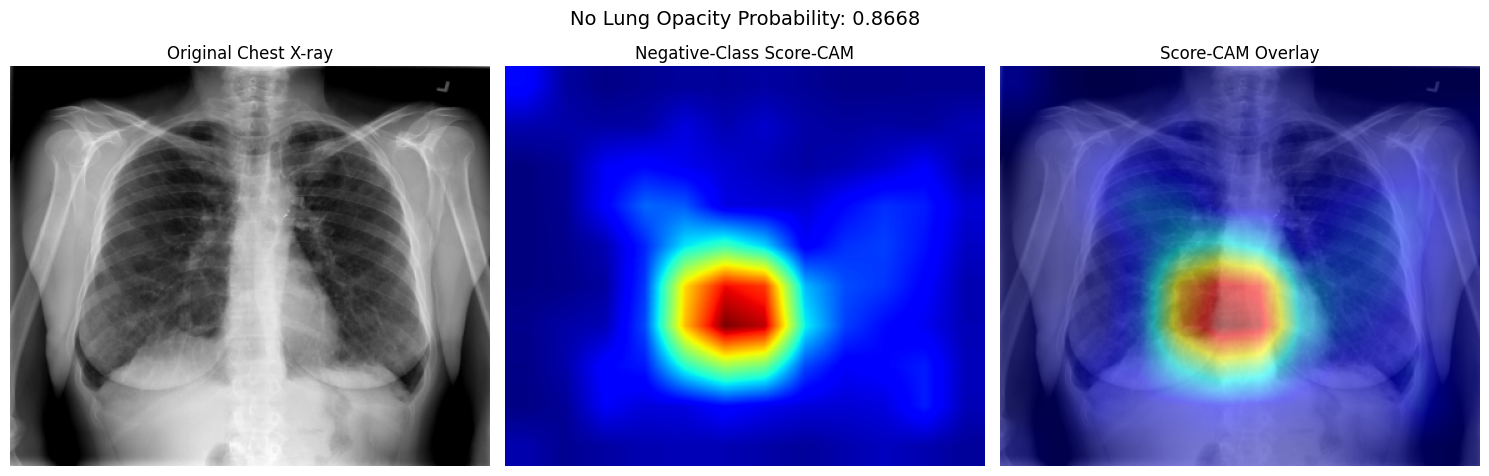

Saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ScoreCAM/negative_scorecam_example_1.png
Lung opacity probability: 0.1332
No lung opacity probability: 0.8668


In [ ]:
import matplotlib.pyplot as plt
from pytorch_grad_cam.utils.image import show_cam_on_image

# Select the first true-negative image
row = selected_negatives.iloc[0]
uid = row["sop_uid"]

# Load and resize the chest X-ray
image = load_dicom(dicom_lookup[uid])

resized = cv2.resize(
    image,
    (384, 320),
    interpolation=cv2.INTER_AREA
)

# Prepare model input
input_tensor = prepare_corrupted_image(
    resized
).unsqueeze(0).to(device)

# Get model prediction
with torch.no_grad():
    logit = model(input_tensor).reshape(-1)[0]
    opacity_probability = torch.sigmoid(logit).item()

# Generate negative-class Score-CAM
heatmap = cam(
    input_tensor=input_tensor,
    targets=negative_target
)[0].copy()

# Overlay heatmap on original image
rgb_image = np.stack([resized] * 3, axis=-1)

overlay = show_cam_on_image(
    rgb_image.astype(np.float32),
    heatmap,
    use_rgb=True
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(resized, cmap="gray")
axes[0].set_title("Original Chest X-ray")

axes[1].imshow(heatmap, cmap="jet")
axes[1].set_title("Negative-Class Score-CAM")

axes[2].imshow(overlay)
axes[2].set_title("Score-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"No Lung Opacity Probability: {1 - opacity_probability:.4f}",
    fontsize=14
)

plt.tight_layout()

# Save figure
save_path = SCORECAM_DIR / "negative_scorecam_example_1.png"

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved to:", save_path)
print("Lung opacity probability:", round(opacity_probability, 4))
print("No lung opacity probability:", round(1 - opacity_probability, 4))

In [ ]:
import gc

negative_baseline_heatmaps = {}

for i, row in selected_negatives.iterrows():
    uid = row["sop_uid"]

    image = load_dicom(dicom_lookup[uid])

    resized = cv2.resize(
        image, (384, 320),
        interpolation=cv2.INTER_AREA
    )

    tensor = prepare_corrupted_image(
        resized
    ).unsqueeze(0).to(device)

    heatmap = cam(
        input_tensor=tensor,
        targets=negative_target
    )[0].copy()

    negative_baseline_heatmaps[uid] = heatmap

    # Save heatmap to Google Drive
    np.save(
        SCORECAM_DIR / f"negative_baseline_{i+1}.npy",
        heatmap
    )

    print(f"Image {i+1}/6: baseline saved")

    del image, resized, tensor, heatmap
    gc.collect()

print("\nAll six negative baseline explanations saved.")

100%|██████████| 512/512 [00:21<00:00, 23.35it/s]


Image 1/6: baseline saved


100%|██████████| 512/512 [00:21<00:00, 23.33it/s]


Image 2/6: baseline saved


100%|██████████| 512/512 [00:21<00:00, 24.02it/s]


...

Image 4/6: baseline saved


100%|██████████| 512/512 [00:21<00:00, 23.95it/s]


Image 5/6: baseline saved


100%|██████████| 512/512 [00:21<00:00, 23.85it/s]


Image 6/6: baseline saved

All six negative baseline explanations saved.


In [ ]:
for i in range(1, 7):
    path = SCORECAM_DIR / f"negative_baseline_{i}.npy"
    print(f"Image {i}: {'Saved' if path.exists() else 'Missing'}")

print(
    "\nHeatmaps in memory:",
    len(negative_baseline_heatmaps)
)

Image 1: Saved
Image 2: Saved
Image 3: Saved
Image 4: Saved
Image 5: Saved
Image 6: Saved

Heatmaps in memory: 6


In [ ]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np
import cv2
import gc

negative_blur_path = SCORECAM_DIR / "gaussian_blur_negative_six.csv"

blur_levels = {
    "Original": 0,
    "Mild Blur": 0.5,
    "Moderate Blur": 1.5,
    "Severe Blur": 3.0
}

# Resume from saved results if this cell was interrupted
if negative_blur_path.exists():
    negative_blur_results = pd.read_csv(negative_blur_path).to_dict("records")
else:
    negative_blur_results = []

completed = {
    (str(r["sop_uid"]), str(r["condition"]))
    for r in negative_blur_results
}

cam.batch_size = 4

for i, row in selected_negatives.iterrows():
    uid = row["sop_uid"]
    baseline = np.load(
        SCORECAM_DIR / f"negative_baseline_{i+1}.npy"
    )

    image = load_dicom(dicom_lookup[uid])
    resized = cv2.resize(
        image, (384, 320),
        interpolation=cv2.INTER_AREA
    )

    for condition, sigma in blur_levels.items():

        if (uid, condition) in completed:
            continue

        if sigma == 0:
            corrupted = resized
            heatmap = baseline
        else:
            corrupted = cv2.GaussianBlur(
                resized, (0, 0),
                sigmaX=sigma,
                sigmaY=sigma
            )

        tensor = prepare_corrupted_image(
            corrupted
        ).unsqueeze(0).to(device)

        with torch.no_grad():
            logit = model(tensor).reshape(-1)[0]
            opacity_probability = torch.sigmoid(logit).item()

        if sigma != 0:
            heatmap = cam(
                input_tensor=tensor,
                targets=negative_target
            )[0].copy()

        similarity = spearmanr(
            baseline.ravel(),
            heatmap.ravel()
        ).statistic

        negative_blur_results.append({
            "image": i + 1,
            "sop_uid": uid,
            "condition": condition,
            "sigma": sigma,
            "opacity_probability": opacity_probability,
            "predicted_class": int(opacity_probability >= 0.5),
            "explanation_similarity": similarity
        })

        completed.add((uid, condition))

        # Save after every condition
        pd.DataFrame(negative_blur_results).to_csv(
            negative_blur_path,
            index=False
        )

        print(f"Image {i+1}/6 | {condition}: saved")

        del tensor
        if sigma != 0:
            del heatmap
        gc.collect()

    del image, resized, baseline
    gc.collect()

print("\nNegative-image Gaussian blur experiment complete!")
print("Saved to:", negative_blur_path)

Image 1/6 | Original: saved


100%|██████████| 512/512 [00:22<00:00, 22.98it/s]


Image 1/6 | Mild Blur: saved


100%|██████████| 512/512 [00:22<00:00, 23.19it/s]


Image 1/6 | Moderate Blur: saved


...

Image 6/6 | Mild Blur: saved


100%|██████████| 512/512 [00:21<00:00, 23.99it/s]


Image 6/6 | Moderate Blur: saved


100%|██████████| 512/512 [00:21<00:00, 24.03it/s]


Image 6/6 | Severe Blur: saved

Negative-image Gaussian blur experiment complete!
Saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ScoreCAM/gaussian_blur_negative_six.csv


In [ ]:
negative_blur_df = pd.read_csv(
    SCORECAM_DIR / "gaussian_blur_negative_six.csv"
)

print("Total observations:", len(negative_blur_df))

display(
    negative_blur_df.groupby("condition").agg(
        mean_opacity_probability=("opacity_probability", "mean"),
        mean_explanation_similarity=("explanation_similarity", "mean"),
        positive_predictions=("predicted_class", "sum")
    ).reindex([
        "Original",
        "Mild Blur",
        "Moderate Blur",
        "Severe Blur"
    ]).round(4)
)

Total observations: 24


,mean_opacity_probability,mean_explanation_similarity,positive_predictions
condition,,,
Original,0.0852,1.0000,0
Mild Blur,0.1090,0.9938,0
Moderate Blur,0.3733,0.8536,1
Severe Blur,0.5769,0.7547,6


## Visual Comparison — Negative Images Under Gaussian Blur

100%|██████████| 512/512 [00:20<00:00, 24.40it/s]


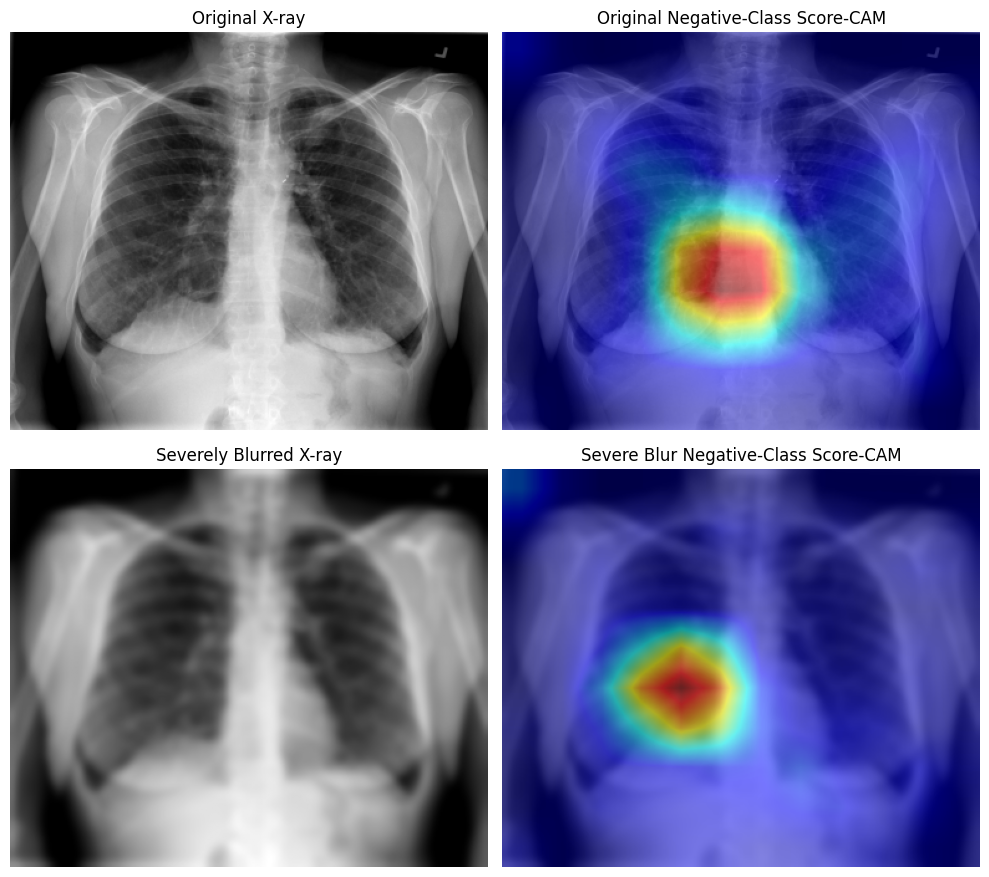

Original opacity probability: 0.1332
Severe blur opacity probability: 0.6468
Saved figure to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ScoreCAM/negative_original_vs_severe_blur_image_1.png


In [ ]:
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt

# Select the first true-negative image
i = 0
row = selected_negatives.iloc[i]
uid = row["sop_uid"]

# Load original image
original = cv2.resize(
    load_dicom(dicom_lookup[uid]),
    (384, 320),
    interpolation=cv2.INTER_AREA
)

# Apply severe Gaussian blur
severe = cv2.GaussianBlur(
    original,
    (0, 0),
    sigmaX=3.0,
    sigmaY=3.0
)

# Load previously saved original Score-CAM
original_cam = np.load(
    SCORECAM_DIR / f"negative_baseline_{i+1}.npy"
)

# Generate Score-CAM for severely blurred image
tensor = prepare_corrupted_image(
    severe
).unsqueeze(0).to(device)

with torch.no_grad():
    severe_probability = torch.sigmoid(
        model(tensor).reshape(-1)[0]
    ).item()

severe_cam = cam(
    input_tensor=tensor,
    targets=negative_target
)[0].copy()

# Create overlays
original_overlay = show_cam_on_image(
    np.stack([original] * 3, axis=-1).astype(np.float32),
    original_cam,
    use_rgb=True
)

severe_overlay = show_cam_on_image(
    np.stack([severe] * 3, axis=-1).astype(np.float32),
    severe_cam,
    use_rgb=True
)

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

axes[0, 0].imshow(original, cmap="gray")
axes[0, 0].set_title("Original X-ray")

axes[0, 1].imshow(original_overlay)
axes[0, 1].set_title(
    "Original Negative-Class Score-CAM"
)

axes[1, 0].imshow(severe, cmap="gray")
axes[1, 0].set_title("Severely Blurred X-ray")

axes[1, 1].imshow(severe_overlay)
axes[1, 1].set_title(
    "Severe Blur Negative-Class Score-CAM"
)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

save_path = (
    SCORECAM_DIR /
    "negative_original_vs_severe_blur_image_1.png"
)

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Original opacity probability:",
      round(row["predicted_probability"], 4))

print("Severe blur opacity probability:",
      round(severe_probability, 4))

print("Saved figure to:", save_path)

100%|██████████| 512/512 [00:22<00:00, 23.09it/s]


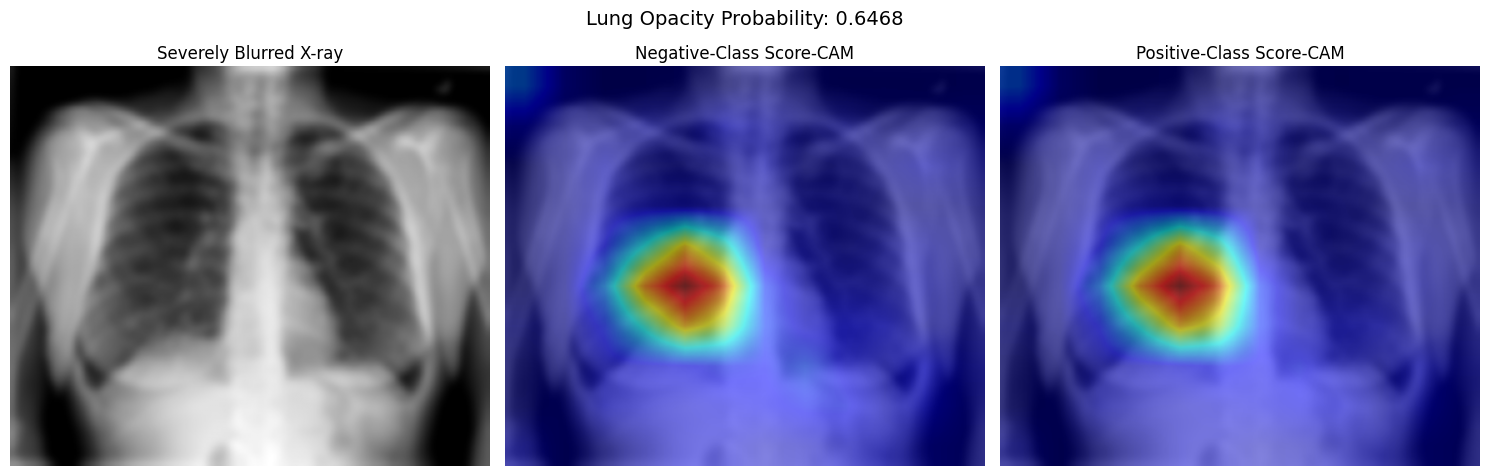

Figure saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ScoreCAM/negative_image_1_false_positive_explanation.png


In [ ]:
# Generate positive-class Score-CAM for the severely blurred image
# Reuse 'tensor' and 'severe' from Step 49

positive_cam = cam(
    input_tensor=tensor,
    targets=[PositiveClassTarget()]
)[0].copy()

# Create overlay
positive_overlay = show_cam_on_image(
    np.stack([severe] * 3, axis=-1).astype(np.float32),
    positive_cam,
    use_rgb=True
)

# Compare the two explanations for the SAME blurred image
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(severe, cmap="gray")
axes[0].set_title("Severely Blurred X-ray")

axes[1].imshow(severe_overlay)
axes[1].set_title("Negative-Class Score-CAM")

axes[2].imshow(positive_overlay)
axes[2].set_title("Positive-Class Score-CAM")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Lung Opacity Probability: {severe_probability:.4f}",
    fontsize=14
)

plt.tight_layout()

save_path = (
    SCORECAM_DIR /
    "negative_image_1_false_positive_explanation.png"
)

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Figure saved to:", save_path)

In [ ]:
from scipy.stats import spearmanr
import numpy as np

correlation = spearmanr(
    severe_cam.ravel(),
    positive_cam.ravel()
).statistic

mean_difference = np.mean(
    np.abs(severe_cam - positive_cam)
)

print("Spearman correlation:", round(correlation, 4))
print("Mean absolute difference:", round(mean_difference, 6))
print(
    "Exactly identical:",
    np.array_equal(severe_cam, positive_cam)
)

Spearman correlation: 0.9973
Mean absolute difference: 0.009536
Exactly identical: False


In [ ]:
# Reuse the original image from Step 49
original_tensor = prepare_corrupted_image(
    original
).unsqueeze(0).to(device)

# Generate positive-class explanation
original_positive_cam = cam(
    input_tensor=original_tensor,
    targets=[PositiveClassTarget()]
)[0].copy()

# Load existing negative-class explanation
original_negative_cam = np.load(
    SCORECAM_DIR / "negative_baseline_1.npy"
)

# Compare
original_corr = spearmanr(
    original_positive_cam.ravel(),
    original_negative_cam.ravel()
).statistic

original_mad = np.mean(
    np.abs(original_positive_cam - original_negative_cam)
)

print("Original image Spearman correlation:", round(original_corr, 4))
print("Original image mean absolute difference:", round(original_mad, 6))

100%|██████████| 512/512 [00:21<00:00, 23.42it/s]


Original image Spearman correlation: 0.9709
Original image mean absolute difference: 0.022047


## 6. Explanation Robustness Under Gaussian Noise

We next evaluate explanation robustness under Gaussian noise.

Unlike Gaussian blur, which smooths image details, Gaussian noise introduces random pixel-level variations. This experiment examines whether Score-CAM explanations are sensitive to these perturbations.

### Noise Conditions

| Condition | Noise Standard Deviation |
|---|---:|
| Original | 0.00 |
| Mild Noise | 0.02 |
| Moderate Noise | 0.05 |
| Severe Noise | 0.10 |

Noise is applied to the normalized grayscale images before model preprocessing.

### Evaluation

For each image and noise condition, we record the predicted lung opacity probability and generate a Score-CAM heatmap.

We compare each corrupted heatmap with its corresponding original heatmap using Spearman rank correlation.

The experiment includes six positive and six negative images, allowing us to investigate how explanation stability varies across noise levels and image classes.

The results are saved for subsequent comparison with the Gaussian blur experiments.

### Interpreting Explanation Stability Under Noise

Spearman rank correlation measures whether the spatial ranking of attribution values is preserved between the original and corrupted images.

A high correlation indicates that the explanation ranking remains similar. However, it does not establish that the explanation remains aligned with radiologist-annotated opacity regions.

Likewise, a low correlation indicates a change in the attribution ranking but does not necessarily imply that localization alignment has worsened.

These are distinct evaluation dimensions:

- **Stability:** How similar are the original and corrupted explanations?
- **Localization alignment:** How much attribution lies inside the annotated opacity regions?

The broader project examines cases where these dimensions disagree.

Gaussian noise is generated with a fixed random seed in the pilot to make the sampled perturbations reproducible. Noise standard deviations are applied to images scaled to the range [0, 1].


In [ ]:
import numpy as np

# Noise standard deviations for images scaled to [0, 1]
noise_levels = {
    "Original": 0.0,
    "Mild Noise": 0.02,
    "Moderate Noise": 0.05,
    "Severe Noise": 0.10
}

def apply_gaussian_noise(image, sigma, seed=42):
    if sigma == 0:
        return image.copy()

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        loc=0.0,
        scale=sigma,
        size=image.shape
    )

    noisy_image = np.clip(
        image + noise,
        0.0,
        1.0
    )

    return noisy_image.astype(np.float32)

print("Gaussian noise levels configured.")

Gaussian noise levels configured.


100%|██████████| 512/512 [00:20<00:00, 24.43it/s]


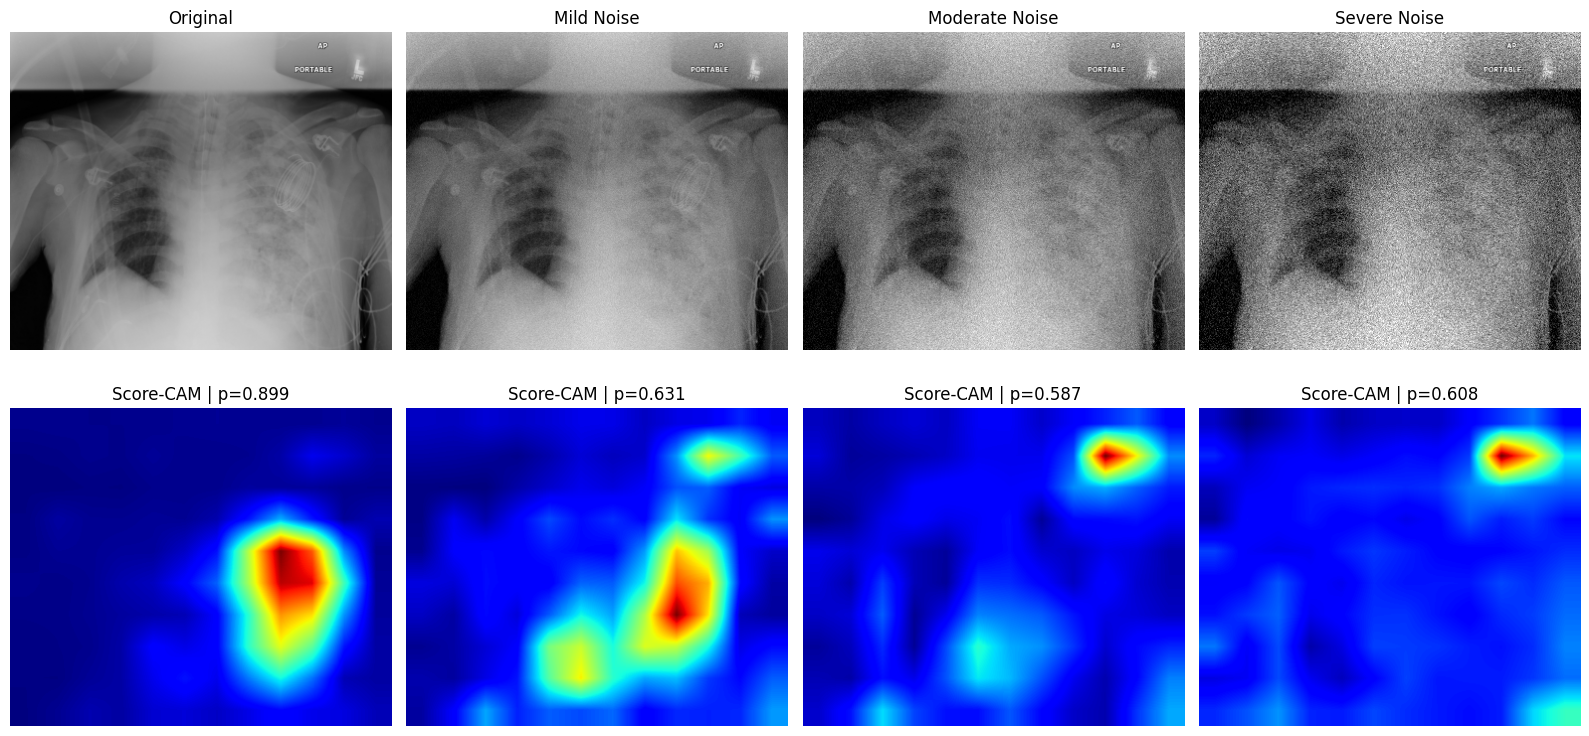

,condition,opacity_probability,explanation_similarity
0,Original,0.8987,1.0000
1,Mild Noise,0.6315,0.8589
2,Moderate Noise,0.5874,0.4117
3,Severe Noise,0.6078,0.3150


In [ ]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# Reuse the first positive image from our earlier experiment
uid = sample_cases.iloc[0]["sop_uid"]

original = cv2.resize(
    load_dicom(dicom_lookup[uid]),
    (384, 320),
    interpolation=cv2.INTER_AREA
)

results = []
baseline_cam = None

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for j, (condition, sigma) in enumerate(noise_levels.items()):

    noisy = apply_gaussian_noise(
        original,
        sigma,
        seed=42
    )

    tensor = prepare_corrupted_image(
        noisy
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        probability = torch.sigmoid(
            model(tensor).reshape(-1)[0]
        ).item()

    heatmap = cam(
        input_tensor=tensor,
        targets=[PositiveClassTarget()]
    )[0].copy()

    if baseline_cam is None:
        baseline_cam = heatmap.copy()

    similarity = spearmanr(
        baseline_cam.ravel(),
        heatmap.ravel()
    ).statistic

    results.append({
        "condition": condition,
        "opacity_probability": probability,
        "explanation_similarity": similarity
    })

    axes[0, j].imshow(noisy, cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(condition)

    axes[1, j].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[1, j].set_title(f"Score-CAM | p={probability:.3f}")

    del tensor, heatmap

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    SCORECAM_DIR / "gaussian_noise_positive_example.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

noise_example_df = pd.DataFrame(results)
display(noise_example_df.round(4))

noise_example_df.to_csv(
    SCORECAM_DIR / "gaussian_noise_positive_example.csv",
    index=False
)

In [ ]:
# Recalculate alignment for the four noise conditions
# using the first positive image

uid = sample_cases.iloc[0]["sop_uid"]

original = cv2.resize(
    load_dicom(dicom_lookup[uid]),
    (384, 320),
    interpolation=cv2.INTER_AREA
)

boxes = opacity_lookup.get(uid, [])

alignment_results = []

for condition, sigma in noise_levels.items():

    noisy = apply_gaussian_noise(
        original, sigma, seed=42
    )

    tensor = prepare_corrupted_image(
        noisy
    ).unsqueeze(0).to(device)

    heatmap = cam(
        input_tensor=tensor,
        targets=[PositiveClassTarget()]
    )[0].copy()

    alignment = calculate_alignment(
        heatmap, boxes
    )

    alignment_results.append({
        "condition": condition,
        "localization_alignment": alignment
    })

    del tensor, heatmap

alignment_df = pd.DataFrame(alignment_results)

display(alignment_df.round(4))

alignment_df.to_csv(
    SCORECAM_DIR / "gaussian_noise_positive_alignment_example.csv",
    index=False
)

100%|██████████| 512/512 [00:20<00:00, 24.52it/s]


,condition,localization_alignment
0,Original,0.6540
1,Mild Noise,0.3665
2,Moderate Noise,0.1440
3,Severe Noise,0.1470


In [ ]:
import pandas as pd
import numpy as np
import gc
from scipy.stats import spearmanr

noise_positive_path = SCORECAM_DIR / "gaussian_noise_positive_six.csv"

# Start from existing results if available
if noise_positive_path.exists():
    noise_results = pd.read_csv(noise_positive_path).to_dict("records")
else:
    noise_results = []

    # Reuse the completed first-image experiment
    example = pd.read_csv(
        SCORECAM_DIR / "gaussian_noise_positive_example.csv"
    )

    alignment = pd.read_csv(
        SCORECAM_DIR / "gaussian_noise_positive_alignment_example.csv"
    )

    first_image = example.merge(
        alignment,
        on="condition"
    )

    first_image["image"] = 1
    first_image["sop_uid"] = sample_cases.iloc[0]["sop_uid"]
    first_image["sigma"] = first_image["condition"].map(noise_levels)

    noise_results = first_image.to_dict("records")

    pd.DataFrame(noise_results).to_csv(
        noise_positive_path,
        index=False
    )

completed = {
    (str(r["sop_uid"]), str(r["condition"]))
    for r in noise_results
}

cam.batch_size = 4

# Images 2–6; image 1 is already complete
for i in range(1, 6):

    row = sample_cases.iloc[i]
    uid = row["sop_uid"]

    print(f"\nProcessing positive image {i+1}/6")

    original = cv2.resize(
        load_dicom(dicom_lookup[uid]),
        (384, 320),
        interpolation=cv2.INTER_AREA
    )

    boxes = opacity_lookup.get(uid, [])

    # Generate original heatmap once per image
    original_tensor = prepare_corrupted_image(
        original
    ).unsqueeze(0).to(device)

    baseline_cam = cam(
        input_tensor=original_tensor,
        targets=[PositiveClassTarget()]
    )[0].copy()

    del original_tensor

    for condition, sigma in noise_levels.items():

        if (uid, condition) in completed:
            continue

        noisy = apply_gaussian_noise(
            original,
            sigma,
            seed=42
        )

        tensor = prepare_corrupted_image(
            noisy
        ).unsqueeze(0).to(device)

        with torch.no_grad():
            probability = torch.sigmoid(
                model(tensor).reshape(-1)[0]
            ).item()

        if sigma == 0:
            heatmap = baseline_cam
        else:
            heatmap = cam(
                input_tensor=tensor,
                targets=[PositiveClassTarget()]
            )[0].copy()

        similarity = spearmanr(
            baseline_cam.ravel(),
            heatmap.ravel()
        ).statistic

        alignment = calculate_alignment(
            heatmap,
            boxes
        )

        noise_results.append({
            "image": i + 1,
            "sop_uid": uid,
            "condition": condition,
            "sigma": sigma,
            "opacity_probability": probability,
            "predicted_class": int(probability >= 0.5),
            "explanation_similarity": similarity,
            "localization_alignment": alignment
        })

        completed.add((uid, condition))

        # Save immediately
        pd.DataFrame(noise_results).to_csv(
            noise_positive_path,
            index=False
        )

        print(f"  {condition}: saved")

        del tensor, noisy

        if sigma != 0:
            del heatmap

        gc.collect()

    del original, baseline_cam
    gc.collect()

print("\nGaussian noise analysis completed!")
print("Results saved to:", noise_positive_path)


Processing positive image 2/6


100%|██████████| 512/512 [00:21<00:00, 24.16it/s]


  Original: saved


100%|██████████| 512/512 [00:21<00:00, 23.38it/s]


  Mild Noise: saved


...

  Mild Noise: saved


100%|██████████| 512/512 [00:21<00:00, 24.19it/s]


  Moderate Noise: saved


100%|██████████| 512/512 [00:21<00:00, 24.18it/s]


  Severe Noise: saved

Gaussian noise analysis completed!
Results saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ScoreCAM/gaussian_noise_positive_six.csv


In [ ]:
positive_noise_df = pd.read_csv(
    SCORECAM_DIR / "gaussian_noise_positive_six.csv"
)

print("Total observations:", len(positive_noise_df))
print("Images completed:", positive_noise_df["sop_uid"].nunique())

noise_summary = (
    positive_noise_df
    .groupby("condition")
    .agg(
        mean_probability=("opacity_probability", "mean"),
        mean_similarity=("explanation_similarity", "mean"),
        mean_alignment=("localization_alignment", "mean"),
        positive_predictions=("predicted_class", "sum")
    )
    .reindex([
        "Original",
        "Mild Noise",
        "Moderate Noise",
        "Severe Noise"
    ])
)

display(noise_summary.round(4))

Total observations: 24
Images completed: 6


,mean_probability,mean_similarity,mean_alignment,positive_predictions
condition,,,,
Original,0.9705,1.0000,0.4574,5.0
Mild Noise,0.7996,0.8042,0.3918,5.0
Moderate Noise,0.6194,0.2860,0.1468,5.0
Severe Noise,0.6157,0.1348,0.1444,5.0


In [ ]:
positive_noise_df["predicted_class_checked"] = (
    positive_noise_df["opacity_probability"] >= 0.5
).astype(int)

display(
    positive_noise_df.groupby("condition").agg(
        images=("sop_uid", "nunique"),
        positive_predictions_saved=("predicted_class", "sum"),
        positive_predictions_checked=("predicted_class_checked", "sum"),
        min_probability=("opacity_probability", "min"),
        max_probability=("opacity_probability", "max")
    ).reindex([
        "Original",
        "Mild Noise",
        "Moderate Noise",
        "Severe Noise"
    ]).round(4)
)

,images,positive_predictions_saved,positive_predictions_checked,min_probability,max_probability
condition,,,,,
Original,6,5.0,6,0.8987,0.9971
Mild Noise,6,5.0,6,0.6315,0.8733
Moderate Noise,6,5.0,6,0.5874,0.6434
Severe Noise,6,5.0,6,0.6078,0.6368


In [ ]:
# Recalculate predicted class from the saved probabilities
positive_noise_df["predicted_class"] = (
    positive_noise_df["opacity_probability"] >= 0.5
).astype(int)

# Remove temporary verification column
positive_noise_df = positive_noise_df.drop(
    columns=["predicted_class_checked"],
    errors="ignore"
)

# Save corrected results to Google Drive
positive_noise_df.to_csv(
    SCORECAM_DIR / "gaussian_noise_positive_six.csv",
    index=False
)

# Verify
display(
    positive_noise_df.groupby("condition")[
        "predicted_class"
    ].sum()
)

print("Corrected results saved successfully.")

,predicted_class
condition,
Mild Noise,6
Moderate Noise,6
Original,6
Severe Noise,6


Corrected results saved successfully.


In [ ]:
import gc

negative_noise_path = SCORECAM_DIR / "gaussian_noise_negative_six.csv"

# Resume from saved results if the experiment was interrupted
if negative_noise_path.exists():
    negative_noise_results = pd.read_csv(
        negative_noise_path
    ).to_dict("records")
else:
    negative_noise_results = []

completed = {
    (str(r["sop_uid"]), str(r["condition"]))
    for r in negative_noise_results
}

cam.batch_size = 4

for i in range(6):

    uid = selected_negatives.iloc[i]["sop_uid"]
    print(f"\nProcessing negative image {i + 1}/6")

    original = cv2.resize(
        load_dicom(dicom_lookup[uid]),
        (384, 320),
        interpolation=cv2.INTER_AREA
    )

    # Reuse previously saved negative-class explanation
    baseline_cam = np.load(
        SCORECAM_DIR / f"negative_baseline_{i + 1}.npy"
    )

    for condition, sigma in noise_levels.items():

        if (uid, condition) in completed:
            continue

        noisy = apply_gaussian_noise(
            original,
            sigma,
            seed=42
        )

        tensor = prepare_corrupted_image(
            noisy
        ).unsqueeze(0).to(device)

        with torch.no_grad():
            probability = torch.sigmoid(
                model(tensor).reshape(-1)[0]
            ).item()

        if sigma == 0:
            heatmap = baseline_cam
        else:
            heatmap = cam(
                input_tensor=tensor,
                targets=negative_target
            )[0].copy()

        similarity = spearmanr(
            baseline_cam.ravel(),
            heatmap.ravel()
        ).statistic

        negative_noise_results.append({
            "image": i + 1,
            "sop_uid": uid,
            "condition": condition,
            "sigma": sigma,
            "opacity_probability": probability,
            "predicted_class": int(probability >= 0.5),
            "explanation_similarity": similarity
        })

        completed.add((uid, condition))

        pd.DataFrame(negative_noise_results).to_csv(
            negative_noise_path,
            index=False
        )

        print(f"  {condition}: saved")

        del tensor, noisy

        if sigma != 0:
            del heatmap

        gc.collect()

    del original, baseline_cam
    gc.collect()

print("\nCompleted Gaussian noise analysis for negative images.")
print("Saved to:", negative_noise_path)


Processing negative image 1/6
  Original: saved


100%|██████████| 512/512 [00:21<00:00, 24.02it/s]


  Mild Noise: saved


100%|██████████| 512/512 [00:21<00:00, 23.57it/s]


  Moderate Noise: saved


...

  Mild Noise: saved


100%|██████████| 512/512 [00:21<00:00, 23.86it/s]


  Moderate Noise: saved


100%|██████████| 512/512 [00:21<00:00, 23.95it/s]


  Severe Noise: saved

Completed Gaussian noise analysis for negative images.
Saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ScoreCAM/gaussian_noise_negative_six.csv


In [ ]:
negative_noise_df = pd.read_csv(
    SCORECAM_DIR / "gaussian_noise_negative_six.csv"
)

print("Total observations:", len(negative_noise_df))
print("Images completed:", negative_noise_df["sop_uid"].nunique())

negative_noise_summary = (
    negative_noise_df
    .groupby("condition")
    .agg(
        mean_opacity_probability=("opacity_probability", "mean"),
        mean_explanation_similarity=("explanation_similarity", "mean"),
        false_positive_predictions=("predicted_class", "sum")
    )
    .reindex([
        "Original",
        "Mild Noise",
        "Moderate Noise",
        "Severe Noise"
    ])
)

display(negative_noise_summary.round(4))

Total observations: 24
Images completed: 6


,mean_opacity_probability,mean_explanation_similarity,false_positive_predictions
condition,,,
Original,0.0852,1.0000,0
Mild Noise,0.2437,0.9373,0
Moderate Noise,0.4102,0.7405,0
Severe Noise,0.5554,0.4313,5


## 7. Comparing Explanation Robustness Across Corruptions

After completing the Gaussian blur and Gaussian noise experiments, we combine the results into a single summary dataset.

The combined analysis considers four experimental groups:

1. Gaussian blur on positive images.
2. Gaussian blur on negative images.
3. Gaussian noise on positive images.
4. Gaussian noise on negative images.

For each corruption condition, we summarize:

- Mean predicted lung opacity probability.
- Mean explanation similarity.
- Number of positive predictions.
- Number of unique images evaluated.

This analysis allows us to compare the effects of different image corruptions on both model predictions and Score-CAM explanations.

In particular, we are interested in whether prediction stability and explanation stability behave similarly.

A model may maintain its original prediction while producing a substantially different explanation. Such cases are relevant when evaluating the reliability of post-hoc explanations in medical imaging.

In [ ]:
import pandas as pd

files = {
    ("Gaussian Blur", "Positive"): "gaussian_blur_all_six.csv",
    ("Gaussian Blur", "Negative"): "gaussian_blur_negative_six.csv",
    ("Gaussian Noise", "Positive"): "gaussian_noise_positive_six.csv",
    ("Gaussian Noise", "Negative"): "gaussian_noise_negative_six.csv",
}

summaries = []

for (corruption, image_group), filename in files.items():

    df = pd.read_csv(SCORECAM_DIR / filename)

    # Recalculate classifications consistently
    df["predicted_class"] = (
        df["opacity_probability"] >= 0.5
    ).astype(int)

    summary = (
        df.groupby("condition", as_index=False)
        .agg(
            mean_opacity_probability=("opacity_probability", "mean"),
            mean_explanation_similarity=("explanation_similarity", "mean"),
            positive_predictions=("predicted_class", "sum"),
            images=("sop_uid", "nunique")
        )
    )

    summary["corruption"] = corruption
    summary["image_group"] = image_group

    summaries.append(summary)

combined_summary = pd.concat(summaries, ignore_index=True)

combined_summary.to_csv(
    SCORECAM_DIR / "scorecam_combined_summary.csv",
    index=False
)

display(combined_summary.round(4))

print("Combined Score-CAM summary saved!")

,condition,mean_opacity_probability,mean_explanation_similarity,positive_predictions,images,corruption,image_group
0,Mild Blur,0.9710,0.9962,6,6,Gaussian Blur,Positive
1,Moderate Blur,0.9131,0.9466,6,6,Gaussian Blur,Positive
2,Original,0.9705,1.0000,6,6,Gaussian Blur,Positive
3,Severe Blur,0.8144,0.8607,6,6,Gaussian Blur,Positive
4,Mild Blur,0.1090,0.9938,0,6,Gaussian Blur,Negative
5,Moderate Blur,0.3733,0.8536,1,6,Gaussian Blur,Negative
6,Original,0.0852,1.0000,0,6,Gaussian Blur,Negative
7,Severe Blur,0.5769,0.7547,6,6,Gaussian Blur,Negative
8,Mild Noise,0.7996,0.8042,6,6,Gaussian Noise,Positive
9,Moderate Noise,0.6194,0.2860,6,6,Gaussian Noise,Positive


Combined Score-CAM summary saved!


## 8. Saving Experimental Results and Reproducibility Checks

To support reproducibility and subsequent analysis, we save the selected image identifiers, experimental results, and shared preprocessing utilities.

The selected positive and negative images are preserved to ensure that subsequent experiments use the same test cases.

A shared Python utility module (`xai_utils.py`) is also created to standardize image loading, preprocessing, model initialization, and corruption settings across notebooks.

Finally, we verify that the required model checkpoints, datasets, and experiment output files exist and that the saved experiments contain the expected image identifiers and observations.

These checks help maintain consistency when comparing Score-CAM with other explanation methods in later stages of the project.


### Reproduction Requirements

This notebook is designed for Google Colab and requires access to the project folder in Google Drive.

Required resources include:

- RSNA DICOM chest X-ray files and annotation data.
- `Data/model_dataset_split.csv`.
- `Models/resnet50_best.pth`.
- `Results/resnet50_test_predictions.csv`.
- PyTorch, torchvision, NumPy, pandas, OpenCV, pydicom, SciPy, matplotlib, and the `grad-cam` package.

### Execution Order

1. Mount Google Drive and verify the project paths.
2. Install the required packages.
3. Load the fixed ResNet-50 checkpoint.
4. Prepare DICOM images and the Score-CAM target layer.
5. Generate the original explanations.
6. Examine annotated positive cases.
7. Run the Gaussian blur and Gaussian noise experiments.
8. Save the selected image IDs and experimental results.
9. Verify that the expected output files exist.

### Runtime Considerations

Score-CAM requires multiple forward passes through the classifier and can be computationally expensive.

The notebook uses smaller Score-CAM batch sizes during some experiments to reduce memory requirements.

Several experimental cells also resume from saved CSV files after interruptions. These cells should be executed carefully to avoid unintentionally replacing previously completed results.

The final verification cell checks the existence and structure of required outputs. Exact reproduction also depends on compatible package versions and access to the original data.


In [ ]:
positive_cases_path = (
    SCORECAM_DIR / "selected_true_positive_images.csv"
)

sample_cases.to_csv(
    positive_cases_path,
    index=False
)

print("Saved:", positive_cases_path)
print("Images saved:", len(sample_cases))

display(
    sample_cases[
        ["sop_uid", "target", "predicted_class"]
    ]
)

Saved: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ScoreCAM/selected_true_positive_images.csv
Images saved: 6


,sop_uid,target,predicted_class
0,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,1,1
1,1.2.276.0.7230010.3.1.4.8323329.23771.15178744...,1,1
2,1.2.276.0.7230010.3.1.4.8323329.2309.151787429...,1,1
3,1.2.276.0.7230010.3.1.4.8323329.11891.15178743...,1,1
4,1.2.276.0.7230010.3.1.4.8323329.3251.151787430...,1,1
5,1.2.276.0.7230010.3.1.4.8323329.25616.15178744...,1,1


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")
DATA_DIR = PROJECT_DIR / "Data"
MODEL_DIR = PROJECT_DIR / "Models"
RESULTS_DIR = PROJECT_DIR / "Results"
SCORECAM_DIR = RESULTS_DIR / "ScoreCAM"

# Read existing selections — DO NOT resample
positive_path = SCORECAM_DIR / "selected_true_positive_images.csv"
negative_path = SCORECAM_DIR / "selected_true_negative_images.csv"

assert positive_path.exists(), f"Missing: {positive_path}"
assert negative_path.exists(), f"Missing: {negative_path}"

positive_cases = pd.read_csv(positive_path).copy()
negative_cases = pd.read_csv(negative_path).copy()

assert len(positive_cases) == 6
assert len(negative_cases) == 6

assert (positive_cases["target"] == 1).all()
assert (negative_cases["target"] == 0).all()

# Preserve original image order
positive_cases["pilot_group"] = "Positive"
negative_cases["pilot_group"] = "Negative"

positive_cases["pilot_image_number"] = range(1, 7)
negative_cases["pilot_image_number"] = range(1, 7)

pilot_images = pd.concat(
    [positive_cases, negative_cases],
    ignore_index=True
)

assert pilot_images["sop_uid"].nunique() == 12, (
    "Expected 12 unique image IDs."
)

# Verify these IDs match the completed Score-CAM experiments
for group, filename in [
    ("Positive", "gaussian_blur_all_six.csv"),
    ("Negative", "gaussian_blur_negative_six.csv"),
    ("Positive", "gaussian_noise_positive_six.csv"),
    ("Negative", "gaussian_noise_negative_six.csv"),
]:
    results = pd.read_csv(SCORECAM_DIR / filename)

    saved_ids = set(
        pilot_images.loc[
            pilot_images["pilot_group"] == group,
            "sop_uid"
        ].astype(str)
    )

    experiment_ids = set(results["sop_uid"].astype(str))

    assert saved_ids == experiment_ids, (
        f"Image ID mismatch in {filename}"
    )

# Save shared pilot dataset
pilot_path = DATA_DIR / "pilot_selected_images.csv"
pilot_images.to_csv(pilot_path, index=False)

print("Pilot dataset saved:", pilot_path)
print("Total images:", len(pilot_images))
print("Unique images:", pilot_images["sop_uid"].nunique())

display(
    pilot_images[
        [
            "pilot_group",
            "pilot_image_number",
            "sop_uid",
            "target",
            "predicted_class",
            "predicted_probability"
        ]
    ]
)

print("\nAll image IDs match your completed Score-CAM experiments.")

Pilot dataset saved: /content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pilot_selected_images.csv
Total images: 12
Unique images: 12


,pilot_group,pilot_image_number,sop_uid,target,predicted_class,predicted_probability
0,Positive,1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,1,1,0.898721
1,Positive,2,1.2.276.0.7230010.3.1.4.8323329.23771.15178744...,1,1,0.997148
2,Positive,3,1.2.276.0.7230010.3.1.4.8323329.2309.151787429...,1,1,0.981664
3,Positive,4,1.2.276.0.7230010.3.1.4.8323329.11891.15178743...,1,1,0.970942
4,Positive,5,1.2.276.0.7230010.3.1.4.8323329.3251.151787430...,1,1,0.981784
5,Positive,6,1.2.276.0.7230010.3.1.4.8323329.25616.15178744...,1,1,0.992467
6,Negative,1,1.2.276.0.7230010.3.1.4.8323329.13578.15178743...,0,0,0.133150
7,Negative,2,1.2.276.0.7230010.3.1.4.8323329.8295.151787433...,0,0,0.011427
8,Negative,3,1.2.276.0.7230010.3.1.4.8323329.6215.151787432...,0,0,0.077130
9,Negative,4,1.2.276.0.7230010.3.1.4.8323329.8937.151787434...,0,0,0.199380



All image IDs match your completed Score-CAM experiments.


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")
utils_path = PROJECT_DIR / "xai_utils.py"

utils_code = '''
import numpy as np
import cv2
import pydicom
import torch

from pathlib import Path
from torchvision import transforms, models


IMAGE_WIDTH = 384
IMAGE_HEIGHT = 320

BLUR_LEVELS = {
    "Original": 0.0,
    "Mild Blur": 0.5,
    "Moderate Blur": 1.5,
    "Severe Blur": 3.0
}

NOISE_LEVELS = {
    "Original": 0.0,
    "Mild Noise": 0.02,
    "Moderate Noise": 0.05,
    "Severe Noise": 0.10
}


def load_dicom(path):
    ds = pydicom.dcmread(str(path))
    image = ds.pixel_array.astype(np.float32)

    if ds.PhotometricInterpretation == "MONOCHROME1":
        image = image.max() - image

    min_val = image.min()
    max_val = image.max()

    if max_val > min_val:
        image = (image - min_val) / (max_val - min_val)
    else:
        image = np.zeros_like(image)

    return image


class MedicalImageTransform:
    def __init__(self):
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __call__(self, image):
        image = cv2.resize(
            np.asarray(image, dtype=np.float32),
            (IMAGE_WIDTH, IMAGE_HEIGHT),
            interpolation=cv2.INTER_AREA
        )

        image = np.stack([image, image, image], axis=0)

        return self.normalize(
            torch.from_numpy(image).float()
        )


medical_transform = MedicalImageTransform()


def prepare_corrupted_image(image):
    # Expects a resized grayscale image in [0, 1]
    rgb = np.stack([image, image, image], axis=0)

    tensor = torch.from_numpy(
        rgb.astype(np.float32)
    )

    return medical_transform.normalize(tensor)


def resize_image(image):
    return cv2.resize(
        np.asarray(image, dtype=np.float32),
        (IMAGE_WIDTH, IMAGE_HEIGHT),
        interpolation=cv2.INTER_AREA
    )


def apply_gaussian_blur(image, sigma):
    if sigma == 0:
        return image.copy()

    return cv2.GaussianBlur(
        image,
        (0, 0),
        sigmaX=sigma,
        sigmaY=sigma
    )


def apply_gaussian_noise(image, sigma, seed=42):
    if sigma == 0:
        return image.copy()

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        loc=0.0,
        scale=sigma,
        size=image.shape
    )

    noisy_image = np.clip(
        image + noise,
        0.0,
        1.0
    )

    return noisy_image.astype(np.float32)


def build_opacity_lookup(annotation_records):
    # Final adjudicated lung-opacity boxes only
    lookup = {}

    for record in annotation_records:
        if (
            record.get("labelId") == "L_v8n"
            and isinstance(record.get("data"), dict)
        ):
            uid = str(record["SOPInstanceUID"])
            lookup.setdefault(uid, []).append(record)

    return lookup


def calculate_alignment(cam_map, boxes):
    h, w = cam_map.shape
    mask = np.zeros((h, w), dtype=bool)

    for record in boxes:
        box = record["data"]

        sx = w / record["width"]
        sy = h / record["height"]

        x1 = int(np.floor(box["x"] * sx))
        y1 = int(np.floor(box["y"] * sy))
        x2 = int(np.ceil((box["x"] + box["width"]) * sx))
        y2 = int(np.ceil((box["y"] + box["height"]) * sy))

        x1, x2 = np.clip([x1, x2], 0, w)
        y1, y2 = np.clip([y1, y2], 0, h)

        mask[y1:y2, x1:x2] = True

    total = cam_map.sum()

    return (
        float(cam_map[mask].sum() / total)
        if total > 0 else np.nan
    )


def load_trained_model(checkpoint_path, device):
    model = models.resnet50(
        weights=None,
        num_classes=1
    )

    # Only load checkpoints you trust
    checkpoint = torch.load(
        str(checkpoint_path),
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    return model.to(device).eval()
'''

utils_path.write_text(utils_code, encoding="utf-8")

# Verify the module is valid Python
import ast
ast.parse(utils_path.read_text(encoding="utf-8"))

print("Reusable XAI utilities saved successfully!")
print("Location:", utils_path)

Reusable XAI utilities saved successfully!
Location: /content/drive/MyDrive/XAI_project_Expo_1_folder/xai_utils.py


In [ ]:
import sys
import importlib
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")
DATA_DIR = PROJECT_DIR / "Data"
MODEL_DIR = PROJECT_DIR / "Models"
RESULTS_DIR = PROJECT_DIR / "Results"
SCORECAM_DIR = RESULTS_DIR / "ScoreCAM"

sys.path.insert(0, str(PROJECT_DIR))

importlib.invalidate_caches()
import xai_utils

required_files = [
    MODEL_DIR / "resnet50_best.pth",
    DATA_DIR / "model_dataset_split.csv",
    DATA_DIR / "pilot_selected_images.csv",
    RESULTS_DIR / "resnet50_test_predictions.csv",
    SCORECAM_DIR / "selected_true_positive_images.csv",
    SCORECAM_DIR / "selected_true_negative_images.csv",
    SCORECAM_DIR / "gaussian_blur_all_six.csv",
    SCORECAM_DIR / "gaussian_blur_negative_six.csv",
    SCORECAM_DIR / "gaussian_noise_positive_six.csv",
    SCORECAM_DIR / "gaussian_noise_negative_six.csv",
    SCORECAM_DIR / "scorecam_combined_summary.csv",
    PROJECT_DIR / "xai_utils.py",
]

missing = [str(p) for p in required_files if not p.is_file()]

for path in required_files:
    print(("OK" if path.is_file() else "MISSING"), path.name)

assert not missing, f"Missing files: {missing}"

pilot = pd.read_csv(DATA_DIR / "pilot_selected_images.csv")
assert len(pilot) == 12
assert pilot["sop_uid"].nunique() == 12

for name in [
    "gaussian_blur_all_six.csv",
    "gaussian_blur_negative_six.csv",
    "gaussian_noise_positive_six.csv",
    "gaussian_noise_negative_six.csv",
]:
    df = pd.read_csv(SCORECAM_DIR / name)
    assert len(df) == 24, f"Unexpected row count in {name}"
    assert df["sop_uid"].nunique() == 6

summary = pd.read_csv(
    SCORECAM_DIR / "scorecam_combined_summary.csv"
)
assert len(summary) == 16

print("\nAll essential files and result counts verified!")
print("Shared utility module imported successfully!")

OK resnet50_best.pth
OK model_dataset_split.csv
OK pilot_selected_images.csv
OK resnet50_test_predictions.csv
OK selected_true_positive_images.csv
OK selected_true_negative_images.csv
OK gaussian_blur_all_six.csv
OK gaussian_blur_negative_six.csv
OK gaussian_noise_positive_six.csv
OK gaussian_noise_negative_six.csv
OK scorecam_combined_summary.csv
OK xai_utils.py

All essential files and result counts verified!
Shared utility module imported successfully!



## 9. Summary and Contribution to the Final XAI Audit

This notebook implemented Score-CAM for the trained ResNet-50 lung-opacity classifier and established an initial explanation-robustness evaluation workflow.

### Completed Work

- Loaded the selected ResNet-50 checkpoint from Notebook 02.
- Generated Score-CAM explanations for positive and negative test images.
- Compared positive-case explanations with radiologist-annotated opacity regions.
- Calculated localization alignment for the annotated pilot images.
- Evaluated Score-CAM explanations under three severity levels of Gaussian blur and Gaussian noise.
- Measured explanation similarity using Spearman rank correlation.
- Saved selected image identifiers, experiment results, and reusable utilities.

### Connection to the Research Question

The central question of the project is whether stable explanations necessarily preserve localization alignment.

This notebook establishes the Score-CAM component of that investigation.

Prediction stability, explanation stability, and localization alignment are treated as different quantities. Agreement in one does not automatically imply agreement in another.

The larger stability–localization disagreement audit is conducted in subsequent notebooks using a broader held-out image sample and comparisons with Integrated Gradients and Occlusion Sensitivity.

### Limitations

The pilot uses only 12 correctly classified images and is not representative of the complete test set.

The annotation analysis focuses on positive cases with available opacity bounding boxes.

Spearman correlation measures attribution-rank similarity, not explanation faithfulness.

Bounding-box alignment provides a spatial reference but does not establish clinical correctness.

Finally, the evaluation is limited to one classifier and one chest X-ray dataset.

### Next Steps

Use the saved pilot image selections and shared utilities to support consistent explanation generation across methods.

The subsequent analysis evaluates stability and localization jointly, including cases where explanation rankings remain stable despite reduced attribution inside annotated opacity regions.
